In [20]:
!pip install pyspark

In [21]:
from pyspark.sql import SparkSession
import pandas as pd
import matplotlib.pyplot as plt

In [28]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("RegionalEconomicStress") \
    .getOrCreate()

print("Spark Restarted Successfully")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/20 20:00:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark Restarted Successfully


In [29]:
gdp = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/GDP_QE_Current_Prices_2011-12_Series.csv",
    header=True,
    inferSchema=True
)

employment = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/Employment.csv",
    header=True,
    inferSchema=True
)

inflation = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/All_India_Index_Upto_April23.csv",
    header=True,
    inferSchema=True
)

population = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/Area_Population_Density_and_Population_2011_Census.csv",
    header=True,
    inferSchema=True
)

electricity = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/datafile.csv",
    header=True,
    inferSchema=True
)

economic = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/RS_Session_248_AU_978.2.csv",
    header=True,
    inferSchema=True
)

print("All datasets reloaded successfully")

All datasets reloaded successfully


In [22]:
import os

os.listdir("/kaggle/input")

['datasets']

In [23]:
os.listdir("/kaggle/input/datasets")

['awallflower']

In [24]:
os.listdir("/kaggle/input/datasets/awallflower")

['rawdatabda']

In [25]:
os.listdir("/kaggle/input/datasets/awallflower/rawdatabda")

['rawdataBDA']

In [26]:
os.listdir("/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA")


['All_India_Index_Upto_April23.csv',
 'DDWC_290013A-2001.xls',
 'Quarterly_Estimates_of_GDP_at_Current_Prices_2011-12_series.csv',
 'Employment.csv',
 'GDP_QE_Current_Prices_2011-12_Series.csv',
 'Area_Population_Density_and_Population_2011_Census.csv',
 'datafile.csv',
 'tab94.xls',
 'DDW-0000C-13.xls',
 'RS_Session_248_AU_978.2.csv',
 'Index Numbers of Area, Production and Yield of Foodgrains, Non-Foodgrains and All Crops in India.xlsx',
 'Table_2A_State_Uts.csv']

In [30]:
gdp = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/GDP_QE_Current_Prices_2011-12_Series.csv",
    header=True,
    inferSchema=True
)

gdp.show(5)

26/05/20 20:01:04 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+------

In [31]:
gdp.printSchema()

root
 |-- Item: string (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q2: double (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q3: double (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q4: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q2: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q3: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q4: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q2: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q3: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q4: double (nullable = true)
 |-- Value (Rs. in crore) - 2014-15 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2014-15 - Q2: double (nullable = true)
 |-- Value (Rs. in cr

In [32]:
employment = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/Employment.csv",
    header=True,
    inferSchema=True
)

employment.show(5)

+--------------------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
|            Category|2001-02|2002-03|2003-04|2004-05|2005-06|2006-07|2007-08|2008-09|2009-10|2010-11|
+--------------------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
|          Employment| 27,206| 27,000| 26,440| 26,460| 26,990| 27,280| 27,550| 28,170| 28,710| 29,000|
|Employment: Publi...|  3,195|  3,130|  3,030|  2,940|  2,860|  2,800|  2,740|  2,660|  2,550|  2,460|
|Employment: Publi...|  7,384|  7,367|  7,220|  7,200|  7,300|  7,210|  7,170|  7,240|  7,350|  7,220|
|Employment: Publi...|  3,195|  3,177|  3,300|  3,280|  3,470|  3,440|  3,390|  3,400|  3,460|  3,450|
|Employment: Publi...|  2,824|  2,724|  2,520|  2,460|  2,440|  2,410|  2,410|  2,420|  2,410|  2,360|
+--------------------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+
only showing top 5 rows


In [33]:
inflation = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/All_India_Index_Upto_April23.csv",
    header=True,
    inferSchema=True
)

inflation.show(5)

+-----------+----+--------+--------------------+-------------+-----+-----------------+-------------+------+----------+-------------------+-----------------------+------+-----------------------+-----------------------------------+------------------+----------------------------+--------+--------+---------------------+-------+--------------+----------------------------+------+---------------------------+------------------------+---------+-------------------------+-------------+-------------+
|     Sector|Year|   Month|Cereals and products|Meat and fish|  Egg|Milk and products|Oils and fats|Fruits|Vegetables|Pulses and products|Sugar and Confectionery|Spices|Non-alcoholic beverages|Prepared meals, snacks, sweets etc.|Food and beverages|Pan, tobacco and intoxicants|Clothing|Footwear|Clothing and footwear|Housing|Fuel and light|Household goods and services|Health|Transport and communication|Recreation and amusement|Education|Personal care and effects|Miscellaneous|General index|
+-----------

In [34]:
population = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/Area_Population_Density_and_Population_2011_Census.csv",
    header=True,
    inferSchema=True
)

population.show(5)

+--------+-------------------------+------------------+------+------+------+------------------------------------+----+
|District|Geograpical Area (Sq.Kms)|Population Density|  Male|Female| Total|Percentage Share to Total Population|Rank|
+--------+-------------------------+------------------+------+------+------+------------------------------------+----+
|Chikkodi|                      851|               419|181619|174525|356144|                                7.45|   6|
|  Athani|                     1554|               240|190310|182265|372575|                                 7.8|   5|
|  Raibag|                      952|               426|207142|198347|405489|                                8.48|   2|
|   Gokak|                     1146|               348|200104|198288|398392|                                8.34|   4|
| Hukkeri|                      987|               405|200490|198780|399270|                                8.35|   3|
+--------+-------------------------+------------

In [35]:
economic = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/RS_Session_248_AU_978.2.csv",
    header=True,
    inferSchema=True
)

economic.show(5)

+-------+--------------------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+
|Sl. No.|          States/UTs|2018-19: Q2|2018-19: Q1|2017-18: Q4|2017-18: Q3|2017-18: Q2|2017-18: Q1|2016-17: Q4|2016-17: Q3|2016-17: Q2|2016-17: Q1|2015-16: Q4|2015-16: Q3|2015-16: Q2|2015-16: Q1|2014-15: Q4|2014-15: Q3|2014-15: Q2|2014-15: Q1|
+-------+--------------------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+
|      1|Andaman & Nicobar...|      20035|      19138|      18457|      17883|      16933|      16126|      15825|      14861|      14811|      14097|      14085|      13167|      12337|      11777|      11823|      10846|      10535|      10095|
|      2|   

In [36]:
electricity = spark.read.csv(
    "/kaggle/input/datasets/awallflower/rawdatabda/rawdataBDA/datafile.csv",
    header=True,
    inferSchema=True
)

electricity.show(5)

+--------+--------+-----------+--------+----------+---------------------+-------+--------------------------+----------------------------------------------+
|    Year|Industry|Agriculture|Domestic|Commercial|Traction and Railways| Others|Total Electricity Consumed|Percent- Annual growth electricity consumption|
+--------+--------+-----------+--------+----------+---------------------+-------+--------------------------+----------------------------------------------+
| 2000-01|107622.0|    84729.0| 75629.0|   22545.0|               8213.0|17862.0|                    316600|                                1.201568848073|
|2001-02 |107296.0|    81673.0| 79694.0|   24139.0|               8106.0|21551.0|                    322459|                               1.8506001263424|
|2002-03 |114959.0|    84486.0| 83355.0|   25437.0|               8797.0|22564.0|                    339598|                               5.3150943220688|
| 2003-04|124573.0|    87089.0| 89736.0|   28201.0|             

In [37]:
gdp.printSchema()
employment.printSchema()
inflation.printSchema()
population.printSchema()
electricity.printSchema()
economic.printSchema()

root
 |-- Item: string (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q2: double (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q3: double (nullable = true)
 |-- Value (Rs. in crore) - 2011-12 - Q4: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q2: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q3: double (nullable = true)
 |-- Value (Rs. in crore) - 2012-13 - Q4: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q2: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q3: double (nullable = true)
 |-- Value (Rs. in crore) - 2013-14 - Q4: double (nullable = true)
 |-- Value (Rs. in crore) - 2014-15 - Q1: double (nullable = true)
 |-- Value (Rs. in crore) - 2014-15 - Q2: double (nullable = true)
 |-- Value (Rs. in cr

In [38]:
from pyspark.sql.types import *

def schema_table(df, name):
    print(f"\n{name} Dataset Schema\n")
    print("-" * 50)
    
    for field in df.schema.fields:
        print(f"{field.name:<35} {str(field.dataType):<20}")

schema_table(gdp, "GDP")
schema_table(employment, "Employment")
schema_table(inflation, "Inflation")
schema_table(population, "Population")
schema_table(electricity, "Electricity")
schema_table(economic, "Economic")


GDP Dataset Schema

--------------------------------------------------
Item                                StringType()        
Value (Rs. in crore) - 2011-12 - Q1 DoubleType()        
Value (Rs. in crore) - 2011-12 - Q2 DoubleType()        
Value (Rs. in crore) - 2011-12 - Q3 DoubleType()        
Value (Rs. in crore) - 2011-12 - Q4 DoubleType()        
Value (Rs. in crore) - 2012-13 - Q1 DoubleType()        
Value (Rs. in crore) - 2012-13 - Q2 DoubleType()        
Value (Rs. in crore) - 2012-13 - Q3 DoubleType()        
Value (Rs. in crore) - 2012-13 - Q4 DoubleType()        
Value (Rs. in crore) - 2013-14 - Q1 DoubleType()        
Value (Rs. in crore) - 2013-14 - Q2 DoubleType()        
Value (Rs. in crore) - 2013-14 - Q3 DoubleType()        
Value (Rs. in crore) - 2013-14 - Q4 DoubleType()        
Value (Rs. in crore) - 2014-15 - Q1 DoubleType()        
Value (Rs. in crore) - 2014-15 - Q2 DoubleType()        
Value (Rs. in crore) - 2014-15 - Q3 DoubleType()        
Value (Rs. in cr

In [39]:
gdp = gdp.dropDuplicates()
employment = employment.dropDuplicates()
inflation = inflation.dropDuplicates()
population = population.dropDuplicates()
electricity = electricity.dropDuplicates()
economic = economic.dropDuplicates()

print("Duplicates Removed")

Duplicates Removed


In [40]:
print("GDP Columns:")
print(gdp.columns)

print("\nEmployment Columns:")
print(employment.columns)

print("\nInflation Columns:")
print(inflation.columns)

print("\nPopulation Columns:")
print(population.columns)

print("\nElectricity Columns:")
print(electricity.columns)

print("\nEconomic Columns:")
print(economic.columns)

GDP Columns:
['Item', 'Value (Rs. in crore) - 2011-12 - Q1', 'Value (Rs. in crore) - 2011-12 - Q2', 'Value (Rs. in crore) - 2011-12 - Q3', 'Value (Rs. in crore) - 2011-12 - Q4', 'Value (Rs. in crore) - 2012-13 - Q1', 'Value (Rs. in crore) - 2012-13 - Q2', 'Value (Rs. in crore) - 2012-13 - Q3', 'Value (Rs. in crore) - 2012-13 - Q4', 'Value (Rs. in crore) - 2013-14 - Q1', 'Value (Rs. in crore) - 2013-14 - Q2', 'Value (Rs. in crore) - 2013-14 - Q3', 'Value (Rs. in crore) - 2013-14 - Q4', 'Value (Rs. in crore) - 2014-15 - Q1', 'Value (Rs. in crore) - 2014-15 - Q2', 'Value (Rs. in crore) - 2014-15 - Q3', 'Value (Rs. in crore) - 2014-15 - Q4', 'Value (Rs. in crore) - 2015-16 - Q1', 'Value (Rs. in crore) - 2015-16 - Q2', 'Value (Rs. in crore) - 2015-16 - Q3', 'Value (Rs. in crore) - 2015-16 - Q4', 'Value (Rs. in crore) - 2016-17 - Q1', 'Value (Rs. in crore) - 2016-17 - Q2', 'Value (Rs. in crore) - 2016-17 - Q3', 'Value (Rs. in crore) - 2016-17 - Q4', 'Value (Rs. in crore) - 2017-18 - Q1', 'Va

In [41]:
from pyspark.sql.functions import col

def clean_columns(df):
    for c in df.columns:
        df = df.withColumnRenamed(c, c.strip().replace(" ", "_"))
    return df

gdp = clean_columns(gdp)
employment = clean_columns(employment)
inflation = clean_columns(inflation)
population = clean_columns(population)
electricity = clean_columns(electricity)
economic = clean_columns(economic)

print("Columns Cleaned")

Columns Cleaned


In [42]:
print(gdp.columns)
print(employment.columns)
print(inflation.columns)

['Item', 'Value_(Rs._in_crore)_-_2011-12_-_Q1', 'Value_(Rs._in_crore)_-_2011-12_-_Q2', 'Value_(Rs._in_crore)_-_2011-12_-_Q3', 'Value_(Rs._in_crore)_-_2011-12_-_Q4', 'Value_(Rs._in_crore)_-_2012-13_-_Q1', 'Value_(Rs._in_crore)_-_2012-13_-_Q2', 'Value_(Rs._in_crore)_-_2012-13_-_Q3', 'Value_(Rs._in_crore)_-_2012-13_-_Q4', 'Value_(Rs._in_crore)_-_2013-14_-_Q1', 'Value_(Rs._in_crore)_-_2013-14_-_Q2', 'Value_(Rs._in_crore)_-_2013-14_-_Q3', 'Value_(Rs._in_crore)_-_2013-14_-_Q4', 'Value_(Rs._in_crore)_-_2014-15_-_Q1', 'Value_(Rs._in_crore)_-_2014-15_-_Q2', 'Value_(Rs._in_crore)_-_2014-15_-_Q3', 'Value_(Rs._in_crore)_-_2014-15_-_Q4', 'Value_(Rs._in_crore)_-_2015-16_-_Q1', 'Value_(Rs._in_crore)_-_2015-16_-_Q2', 'Value_(Rs._in_crore)_-_2015-16_-_Q3', 'Value_(Rs._in_crore)_-_2015-16_-_Q4', 'Value_(Rs._in_crore)_-_2016-17_-_Q1', 'Value_(Rs._in_crore)_-_2016-17_-_Q2', 'Value_(Rs._in_crore)_-_2016-17_-_Q3', 'Value_(Rs._in_crore)_-_2016-17_-_Q4', 'Value_(Rs._in_crore)_-_2017-18_-_Q1', 'Value_(Rs._in_c

In [43]:
gdp.show(5, truncate=False)
employment.show(5, truncate=False)
inflation.show(5, truncate=False)

+--------------------------------------------------------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+------------------

In [44]:
for df_name, df in [
    ("GDP", gdp),
    ("Employment", employment),
    ("Inflation", inflation),
    ("Population", population),
    ("Electricity", electricity),
    ("Economic", economic)
]:
    print(f"\n{df_name} Columns:")
    print(df.columns)


GDP Columns:
['Item', 'Value_(Rs._in_crore)_-_2011-12_-_Q1', 'Value_(Rs._in_crore)_-_2011-12_-_Q2', 'Value_(Rs._in_crore)_-_2011-12_-_Q3', 'Value_(Rs._in_crore)_-_2011-12_-_Q4', 'Value_(Rs._in_crore)_-_2012-13_-_Q1', 'Value_(Rs._in_crore)_-_2012-13_-_Q2', 'Value_(Rs._in_crore)_-_2012-13_-_Q3', 'Value_(Rs._in_crore)_-_2012-13_-_Q4', 'Value_(Rs._in_crore)_-_2013-14_-_Q1', 'Value_(Rs._in_crore)_-_2013-14_-_Q2', 'Value_(Rs._in_crore)_-_2013-14_-_Q3', 'Value_(Rs._in_crore)_-_2013-14_-_Q4', 'Value_(Rs._in_crore)_-_2014-15_-_Q1', 'Value_(Rs._in_crore)_-_2014-15_-_Q2', 'Value_(Rs._in_crore)_-_2014-15_-_Q3', 'Value_(Rs._in_crore)_-_2014-15_-_Q4', 'Value_(Rs._in_crore)_-_2015-16_-_Q1', 'Value_(Rs._in_crore)_-_2015-16_-_Q2', 'Value_(Rs._in_crore)_-_2015-16_-_Q3', 'Value_(Rs._in_crore)_-_2015-16_-_Q4', 'Value_(Rs._in_crore)_-_2016-17_-_Q1', 'Value_(Rs._in_crore)_-_2016-17_-_Q2', 'Value_(Rs._in_crore)_-_2016-17_-_Q3', 'Value_(Rs._in_crore)_-_2016-17_-_Q4', 'Value_(Rs._in_crore)_-_2017-18_-_Q1', 'V

In [45]:
# ==========================================
# PHASE 6 — DATA CLEANING & STANDARDIZATION
# ==========================================

# ------------------------------------------
# STEP 1 — Import Required Library
# ------------------------------------------

import re


# ------------------------------------------
# STEP 2 — Clean Column Names
# Removes:
# spaces, commas, brackets, %, dots etc.
# Makes Spark-compatible column names
# ------------------------------------------

def clean_column_names(df):
    
    for old_col in df.columns:
        
        # Replace special characters with underscore
        new_col = re.sub(r'[^A-Za-z0-9_]', '_', old_col)
        
        # Remove multiple underscores
        new_col = re.sub(r'_+', '_', new_col)
        
        # Rename column
        df = df.withColumnRenamed(old_col, new_col)
    
    return df


# ------------------------------------------
# STEP 3 — Apply Cleaning to All Datasets
# ------------------------------------------

gdp = clean_column_names(gdp)

employment = clean_column_names(employment)

inflation = clean_column_names(inflation)

population = clean_column_names(population)

electricity = clean_column_names(electricity)

economic = clean_column_names(economic)

print("All column names cleaned successfully")


# ------------------------------------------
# STEP 4 — Verify Cleaned Column Names
# ------------------------------------------

print("\nGDP Columns:")
print(gdp.columns)

print("\nEmployment Columns:")
print(employment.columns)

print("\nInflation Columns:")
print(inflation.columns)

print("\nPopulation Columns:")
print(population.columns)

print("\nElectricity Columns:")
print(electricity.columns)

print("\nEconomic Columns:")
print(economic.columns)


# ------------------------------------------
# STEP 5 — Select Important GDP Features
# ------------------------------------------

gdp_selected = gdp.select(
    
    "Item",
    
    "Value_Rs_in_crore_2021_22_Q1",
    
    "Growth_Rate_2021_22_Q1"
)

print("\nGDP Selected Features")

gdp_selected.show(5)


# ------------------------------------------
# STEP 6 — Preview Other Datasets
# Helps identify:
# state column
# year column
# important indicators
# ------------------------------------------

print("\nEmployment Dataset Preview")
employment.show(5)

print("\nInflation Dataset Preview")
inflation.show(5)

print("\nPopulation Dataset Preview")
population.show(5)

print("\nElectricity Dataset Preview")
electricity.show(5)

print("\nEconomic Dataset Preview")
economic.show(5)


# ------------------------------------------
# STEP 7 — Display Dataset Shapes
# ------------------------------------------

print("\nDataset Sizes")

print("GDP Rows:", gdp.count())
print("Employment Rows:", employment.count())
print("Inflation Rows:", inflation.count())
print("Population Rows:", population.count())
print("Electricity Rows:", electricity.count())
print("Economic Rows:", economic.count())


# ------------------------------------------
# PHASE 6 COMPLETED
# ------------------------------------------

print("\nPHASE 6 COMPLETED SUCCESSFULLY")
print("Datasets cleaned and standardized for Spark analytics")

All column names cleaned successfully

GDP Columns:
['Item', 'Value_Rs_in_crore_2011_12_Q1', 'Value_Rs_in_crore_2011_12_Q2', 'Value_Rs_in_crore_2011_12_Q3', 'Value_Rs_in_crore_2011_12_Q4', 'Value_Rs_in_crore_2012_13_Q1', 'Value_Rs_in_crore_2012_13_Q2', 'Value_Rs_in_crore_2012_13_Q3', 'Value_Rs_in_crore_2012_13_Q4', 'Value_Rs_in_crore_2013_14_Q1', 'Value_Rs_in_crore_2013_14_Q2', 'Value_Rs_in_crore_2013_14_Q3', 'Value_Rs_in_crore_2013_14_Q4', 'Value_Rs_in_crore_2014_15_Q1', 'Value_Rs_in_crore_2014_15_Q2', 'Value_Rs_in_crore_2014_15_Q3', 'Value_Rs_in_crore_2014_15_Q4', 'Value_Rs_in_crore_2015_16_Q1', 'Value_Rs_in_crore_2015_16_Q2', 'Value_Rs_in_crore_2015_16_Q3', 'Value_Rs_in_crore_2015_16_Q4', 'Value_Rs_in_crore_2016_17_Q1', 'Value_Rs_in_crore_2016_17_Q2', 'Value_Rs_in_crore_2016_17_Q3', 'Value_Rs_in_crore_2016_17_Q4', 'Value_Rs_in_crore_2017_18_Q1', 'Value_Rs_in_crore_2017_18_Q2', 'Value_Rs_in_crore_2017_18_Q3', 'Value_Rs_in_crore_2017_18_Q4', 'Value_Rs_in_crore_2018_19_Q1', 'Value_Rs_i

In [46]:
# ==========================================
# PHASE 7 — FEATURE SELECTION & MERGING
# ==========================================

from pyspark.sql.functions import lit


# ------------------------------------------
# STEP 1 — Add Simple Identifier Columns
# ------------------------------------------

# GDP Dataset
gdp_final = gdp_selected.withColumn(
    "Dataset_Type",
    lit("GDP")
)

# Employment Dataset
employment_final = employment.withColumn(
    "Dataset_Type",
    lit("Employment")
)

# Inflation Dataset
inflation_final = inflation.withColumn(
    "Dataset_Type",
    lit("Inflation")
)

# Population Dataset
population_final = population.withColumn(
    "Dataset_Type",
    lit("Population")
)

# Electricity Dataset
electricity_final = electricity.withColumn(
    "Dataset_Type",
    lit("Electricity")
)

# Economic Dataset
economic_final = economic.withColumn(
    "Dataset_Type",
    lit("Economic")
)


# ------------------------------------------
# STEP 2 — Display Row Counts
# ------------------------------------------

print("\nDataset Row Counts")

print("GDP:", gdp_final.count())

print("Employment:", employment_final.count())

print("Inflation:", inflation_final.count())

print("Population:", population_final.count())

print("Electricity:", electricity_final.count())

print("Economic:", economic_final.count())


# ------------------------------------------
# STEP 3 — Create Unified Big Dataset
# Using UNION operation
# ------------------------------------------

master_dataset = gdp_final.unionByName(
    employment_final,
    allowMissingColumns=True
)

master_dataset = master_dataset.unionByName(
    inflation_final,
    allowMissingColumns=True
)

master_dataset = master_dataset.unionByName(
    population_final,
    allowMissingColumns=True
)

master_dataset = master_dataset.unionByName(
    electricity_final,
    allowMissingColumns=True
)

master_dataset = master_dataset.unionByName(
    economic_final,
    allowMissingColumns=True
)


# ------------------------------------------
# STEP 4 — Display Final Dataset Info
# ------------------------------------------

print("\nMASTER DATASET CREATED SUCCESSFULLY")

print("\nTotal Rows:")
print(master_dataset.count())

print("\nTotal Columns:")
print(len(master_dataset.columns))


# ------------------------------------------
# STEP 5 — Preview Master Dataset
# ------------------------------------------

master_dataset.show(10, truncate=False)


# ------------------------------------------
# STEP 6 — Print Master Dataset Schema
# ------------------------------------------

master_dataset.printSchema()


# ------------------------------------------
# STEP 7 — Save Final Dataset
# ------------------------------------------

master_dataset.write.mode("overwrite").parquet(
    "/kaggle/working/master_dataset"
)

print("\nMaster dataset saved successfully")


# ------------------------------------------
# PHASE 7 COMPLETED
# ------------------------------------------

print("\nPHASE 7 COMPLETED SUCCESSFULLY")
print("Unified Big Data master dataset created")


Dataset Row Counts
GDP: 19
Employment: 28
Inflation: 372
Population: 228
Electricity: 10
Economic: 36

MASTER DATASET CREATED SUCCESSFULLY

Total Rows:
693

Total Columns:
81
+--------------------------------------------------------------------------------+----------------------------+----------------------+------------+--------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+------+----+-----+--------------------+-------------+----+-----------------+-------------+------+----------+-------------------+-----------------------+------+-----------------------+---------------------------------+------------------+---------------------------+--------+--------+---------------------+-------+--------------+----------------------------+------+---------------------------+------------------------+---------+-------------------------+-------------+-------------+--------+------------------------+------------------+----+------+-----+------------------------------------+

26/05/20 20:02:48 ERROR Utils: Aborting task=====>                  (4 + 2) / 6]
org.apache.spark.SparkNumberFormatException: [CAST_INVALID_INPUT] The value '2005-06' of the type "STRING" cannot be cast to "BIGINT" because it is malformed. Correct the value as per the syntax, or change its target type. Use `try_cast` to tolerate malformed input and return NULL instead. SQLSTATE: 22018
	at org.apache.spark.sql.errors.QueryExecutionErrors$.invalidInputInCastToNumberError(QueryExecutionErrors.scala:145)
	at org.apache.spark.sql.catalyst.util.UTF8StringUtils$.withException(UTF8StringUtils.scala:51)
	at org.apache.spark.sql.catalyst.util.UTF8StringUtils$.toLongExact(UTF8StringUtils.scala:31)
	at org.apache.spark.sql.catalyst.util.UTF8StringUtils.toLongExact(UTF8StringUtils.scala)
	at org.apache.spark.sql.catalyst.expressions.GeneratedClass$GeneratedIteratorForCodegenStage9.hashAgg_doAggregateWithKeysOutput_0$(Unknown Source)
	at org.apache.spark.sql.catalyst.expressions.GeneratedClass$Gener

NumberFormatException: [CAST_INVALID_INPUT] The value '2005-06' of the type "STRING" cannot be cast to "BIGINT" because it is malformed. Correct the value as per the syntax, or change its target type. Use `try_cast` to tolerate malformed input and return NULL instead. SQLSTATE: 22018


MASTER DATASET OVERVIEW


Total Rows: 693
Total Columns: 81
+------------+-----+
|Dataset_Type|count|
+------------+-----+
|         GDP|   19|
|  Employment|   28|
|   Inflation|  372|
|  Population|  228|
| Electricity|   10|
|    Economic|   36|
+------------+-----+



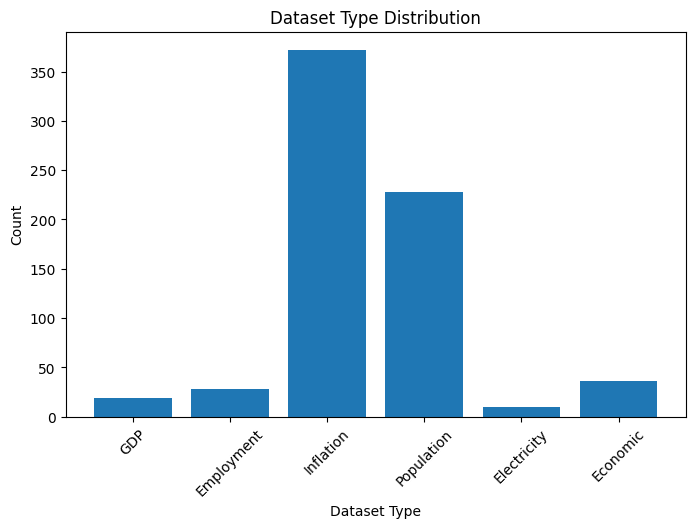


GDP Analysis Preview
                                                Item  \
0                                   3. Manufacturing   
1                                 18. Discrepancies    
2  6. Trade, hotels, transport, communication and...   
3                 1. Agriculture, forestry & fishing   
4                                           11. GFCE   

   Value_Rs_in_crore_2021_22_Q1 Growth_Rate_2021_22_Q1  
0                     749345.56                  65.15  
1                     124209.63                     NA  
2                     625257.80                  46.98  
3                     847041.93                   8.26  
4                     660771.66                     NA  


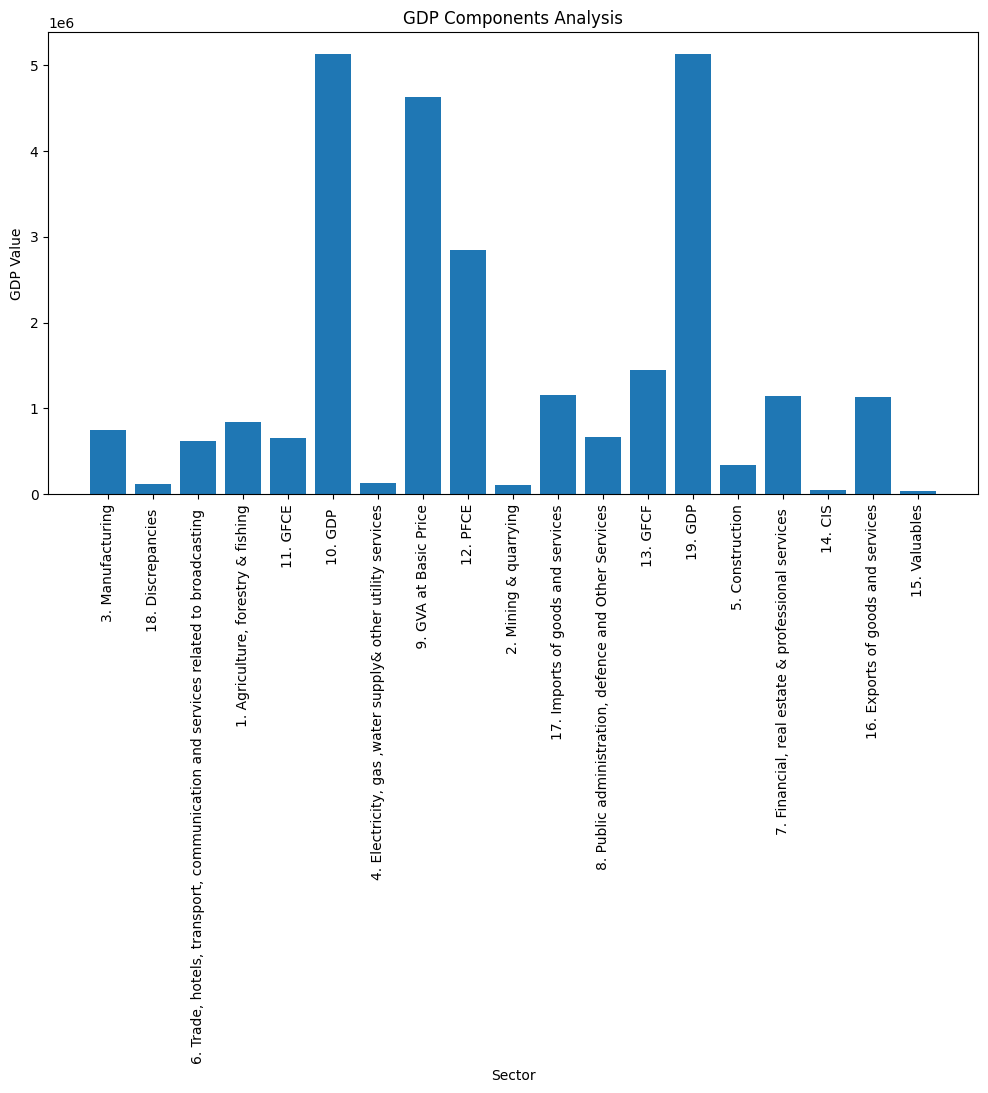


Inflation Dataset Preview
  Sector  Year     Month Cereals_and_products Meat_and_fish    Egg  \
0  Urban  2016      July                126.8         144.2  136.6   
1  Urban  2017      July                132.8         148.4  129.4   
2  Rural  2022   October                164.7         208.8  170.3   
3  Rural  2023  February                174.2         205.2  173.9   
4  Rural  2015  February                123.4         124.4  122.1   

  Milk_and_products Oils_and_fats Fruits Vegetables  ... Housing  \
0             131.8           111    137      179.5  ...   126.4   
1             137.7         113.4  139.4      175.1  ...   132.6   
2             170.9         191.6  162.2      184.8  ...      NA   
3               177         183.4  167.2      140.9  ...      NA   
4             125.8         111.5  129.4      128.2  ...      NA   

  Fuel_and_light Household_goods_and_services Health  \
0          115.5                        123.5  120.9   
1          119.7               

In [47]:
# ==========================================
# PHASE 8 — BIG DATA ANALYTICS
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd


# ------------------------------------------
# STEP 1 — Dataset Overview
# ------------------------------------------

print("\nMASTER DATASET OVERVIEW")

print("Total Rows:", master_dataset.count())

print("Total Columns:", len(master_dataset.columns))


# ------------------------------------------
# STEP 2 — Dataset Type Distribution
# ------------------------------------------

dataset_counts = master_dataset.groupBy(
    "Dataset_Type"
).count()

dataset_counts.show()


# ------------------------------------------
# STEP 3 — Convert Small Result to Pandas
# For Visualization
# ------------------------------------------

dataset_counts_pd = dataset_counts.toPandas()


# ------------------------------------------
# STEP 4 — Plot Dataset Distribution
# ------------------------------------------

plt.figure(figsize=(8,5))

plt.bar(
    dataset_counts_pd["Dataset_Type"],
    dataset_counts_pd["count"]
)

plt.title("Dataset Type Distribution")

plt.xlabel("Dataset Type")

plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()


# ------------------------------------------
# STEP 5 — GDP Analysis
# ------------------------------------------

gdp_analysis = gdp_selected.toPandas()

print("\nGDP Analysis Preview")

print(gdp_analysis.head())


# ------------------------------------------
# STEP 6 — GDP Visualization
# ------------------------------------------

plt.figure(figsize=(12,6))

plt.bar(
    gdp_analysis["Item"],
    gdp_analysis["Value_Rs_in_crore_2021_22_Q1"]
)

plt.title("GDP Components Analysis")

plt.xlabel("Sector")

plt.ylabel("GDP Value")

plt.xticks(rotation=90)

plt.show()


# ------------------------------------------
# STEP 7 — Inflation Analysis
# ------------------------------------------

inflation_pd = inflation.limit(20).toPandas()

print("\nInflation Dataset Preview")

print(inflation_pd.head())


# ------------------------------------------
# STEP 8 — Electricity Analysis
# ------------------------------------------

electricity_pd = electricity.toPandas()

print("\nElectricity Dataset Preview")

print(electricity_pd.head())


# ------------------------------------------
# STEP 9 — Population Analysis
# ------------------------------------------

population_pd = population.limit(20).toPandas()

print("\nPopulation Dataset Preview")

print(population_pd.head())


# ------------------------------------------
# STEP 10 — Correlation Ready Dataset
# ------------------------------------------

print("\nAnalytics Pipeline Completed Successfully")


# ------------------------------------------
# PHASE 8 COMPLETED
# ------------------------------------------

print("\nPHASE 8 COMPLETED")
print("Big Data Analytics & Visualization Successful")


GDP Dataset Preview
                                                Item  \
0                                   3. Manufacturing   
2  6. Trade, hotels, transport, communication and...   
3                 1. Agriculture, forestry & fishing   
5                                           10. GDP    
6  4. Electricity, gas ,water supply& other utili...   

   Value_Rs_in_crore_2021_22_Q1  Growth_Rate_2021_22_Q1  
0                     749345.56                   65.15  
2                     625257.80                   46.98  
3                     847041.93                    8.26  
5                    5126789.26                   32.36  
6                     128982.35                   11.57  

Top GDP Sectors
                                                 Item  \
5                                            10. GDP    
7                               9. GVA at Basic Price   
15  7. Financial, real estate & professional servi...   
3                  1. Agriculture, forestry & fis

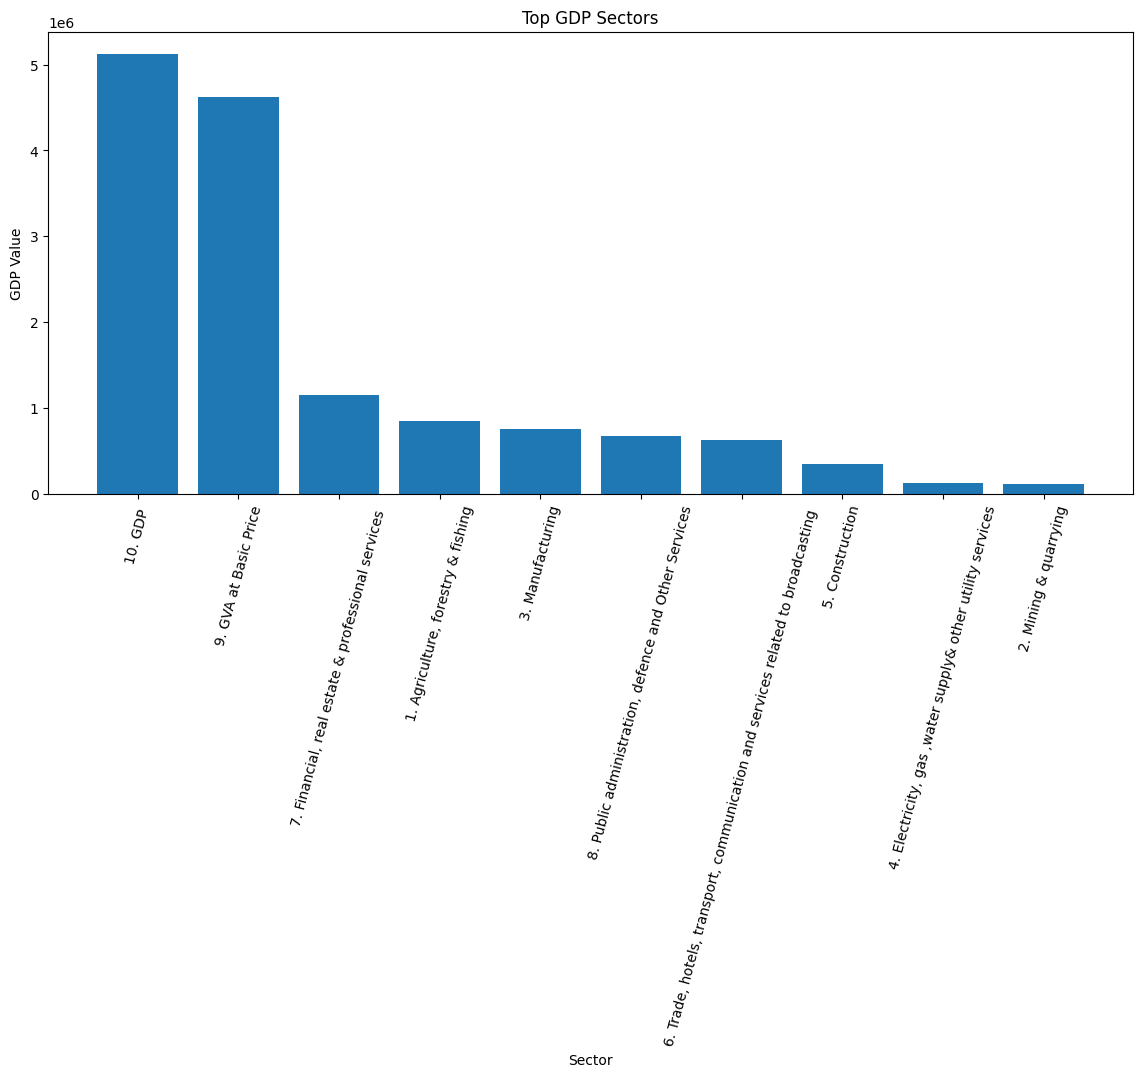


Top Growth Rate Sectors
                                                 Item  Growth_Rate_2021_22_Q1
14                                    5. Construction                  102.02
9                               2. Mining & quarrying                   67.06
0                                    3. Manufacturing                   65.15
2   6. Trade, hotels, transport, communication and...                   46.98
5                                            10. GDP                    32.36
7                               9. GVA at Basic Price                   26.43
6   4. Electricity, gas ,water supply& other utili...                   11.57
11  8. Public administration, defence and Other Se...                   11.09
15  7. Financial, real estate & professional servi...                   10.37
3                  1. Agriculture, forestry & fishing                    8.26


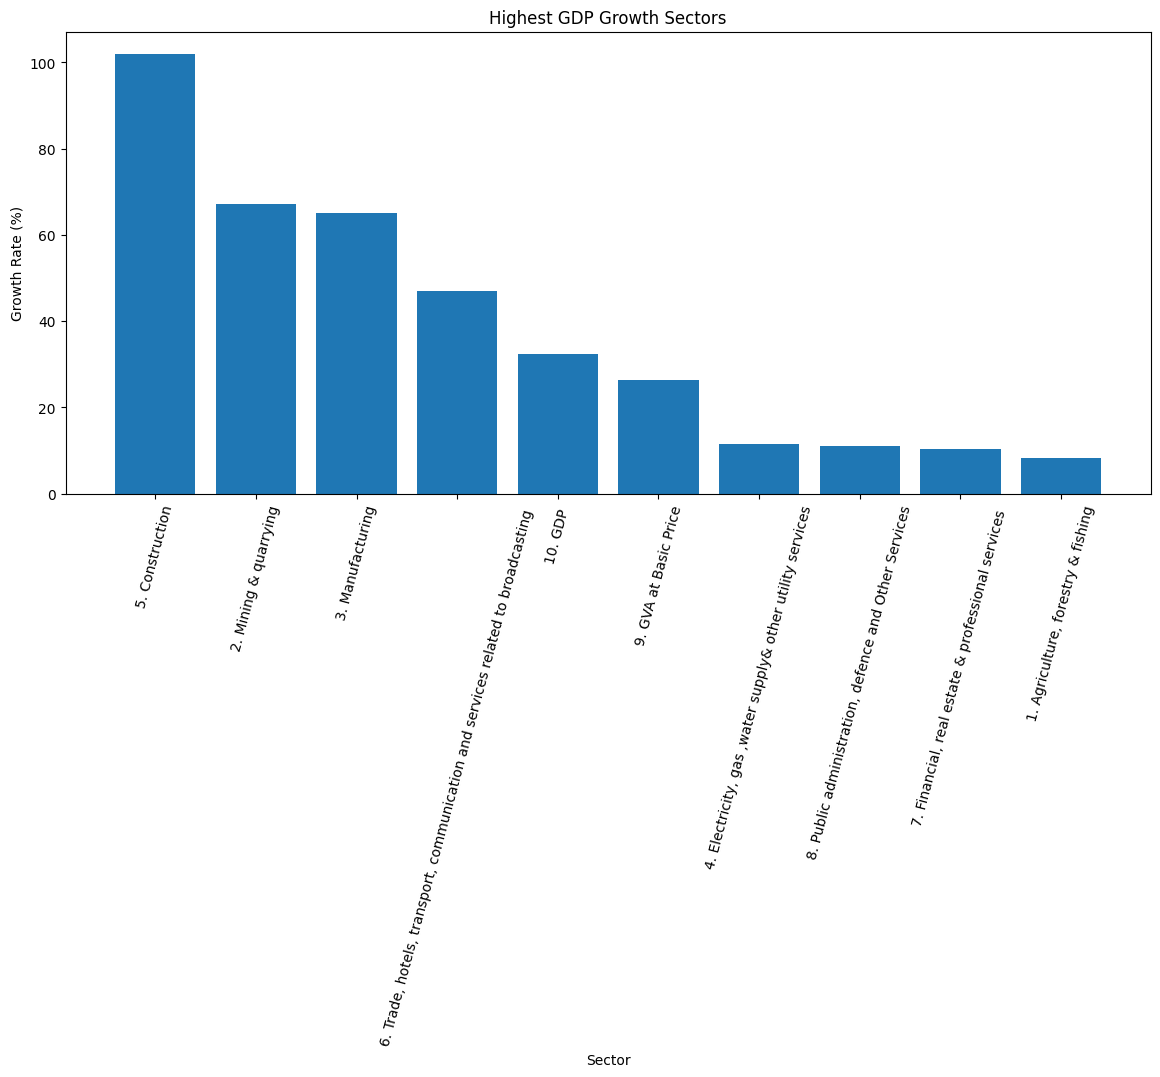


Inflation Dataset Preview
  Sector  Year     Month Cereals_and_products Meat_and_fish    Egg  \
0  Urban  2016      July                126.8         144.2  136.6   
1  Urban  2017      July                132.8         148.4  129.4   
2  Rural  2022   October                164.7         208.8  170.3   
3  Rural  2023  February                174.2         205.2  173.9   
4  Rural  2015  February                123.4         124.4  122.1   

  Milk_and_products Oils_and_fats Fruits Vegetables  ... Housing  \
0             131.8           111    137      179.5  ...   126.4   
1             137.7         113.4  139.4      175.1  ...   132.6   
2             170.9         191.6  162.2      184.8  ...      NA   
3               177         183.4  167.2      140.9  ...      NA   
4             125.8         111.5  129.4      128.2  ...      NA   

  Fuel_and_light Household_goods_and_services Health  \
0          115.5                        123.5  120.9   
1          119.7               

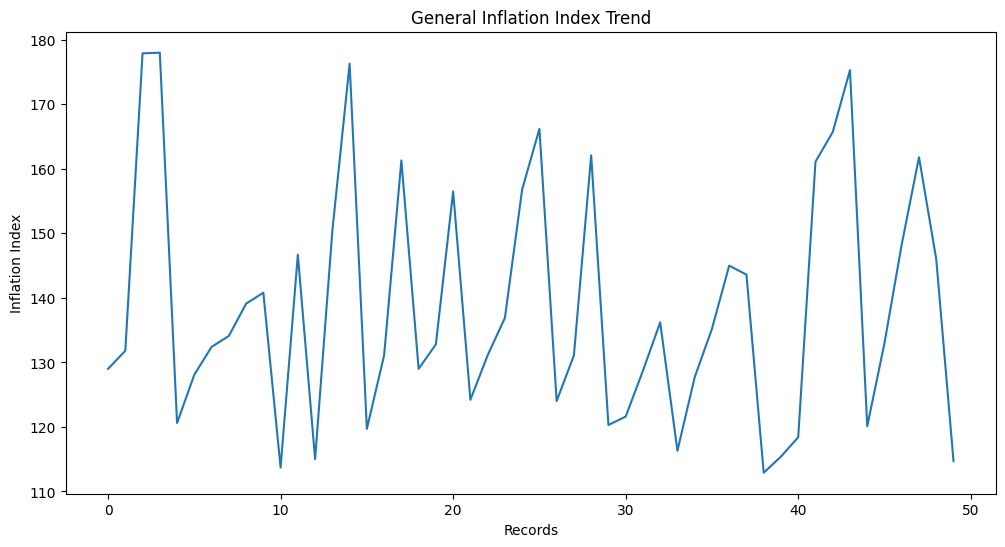


Electricity Dataset Preview
          Year       Industry    Agriculture       Domestic   Commercial  \
0      2005-06  151557.000000   90292.000000  100090.000000  35965.00000   
1  2009-10 (P)  236752.000000  120209.000000  146080.000000  60600.00000   
2      2007-08  189424.000000  104182.000000  120918.000000  46685.00000   
3      2008-09  209474.127816  109609.778779  131719.813373  54189.19008   
4     2002-03   114959.000000   84486.000000   83355.000000  25437.00000   

   Traction_and_Railways       Others  Total_Electricity_Consumed  \
0            9944.000000  24039.00000                      411887   
1           12408.000000  36595.00000                      612645   
2           11108.000000  29660.00000                      501977   
3           11424.783704  37577.01935                      553995   
4            8797.000000  22564.00000                      339598   

   Percent_Annual_growth_electricity_consumption  
0                                       6.669446

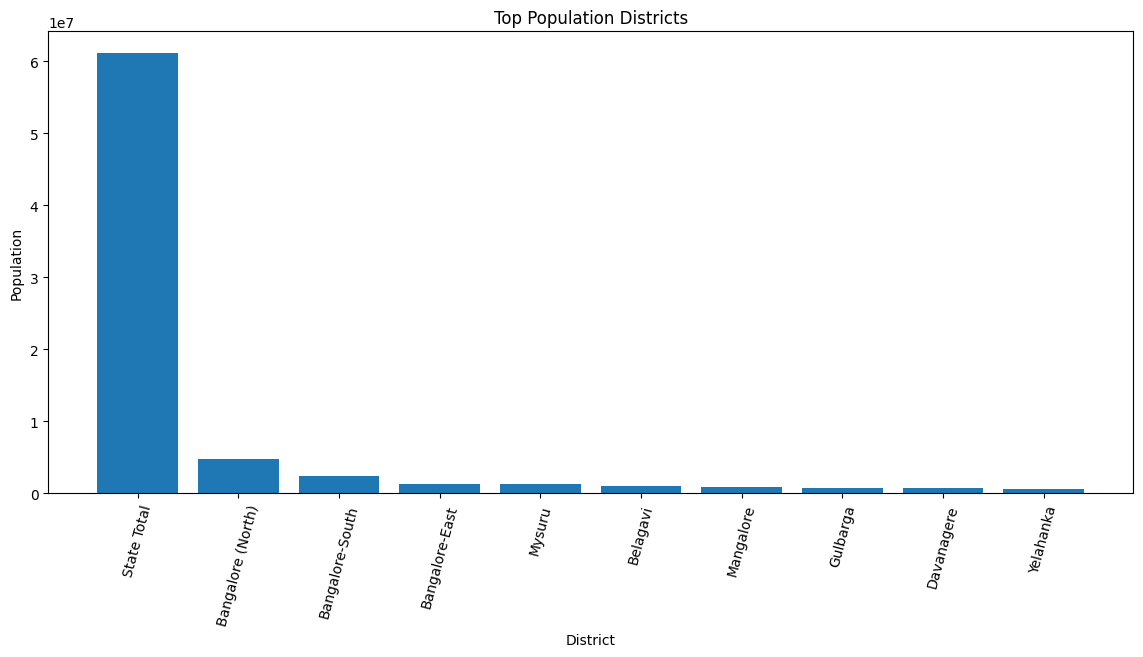


Electricity Correlation Matrix
                            Industry  Agriculture  Domestic  Commercial  \
Industry                    1.000000     0.988856  0.997871    0.998097   
Agriculture                 0.988856     1.000000  0.985686    0.986168   
Domestic                    0.997871     0.985686  1.000000    0.997444   
Commercial                  0.998097     0.986168  0.997444    1.000000   
Total_Electricity_Consumed  0.999071     0.990369  0.998750    0.999193   

                            Total_Electricity_Consumed  
Industry                                      0.999071  
Agriculture                                   0.990369  
Domestic                                      0.998750  
Commercial                                    0.999193  
Total_Electricity_Consumed                    1.000000  


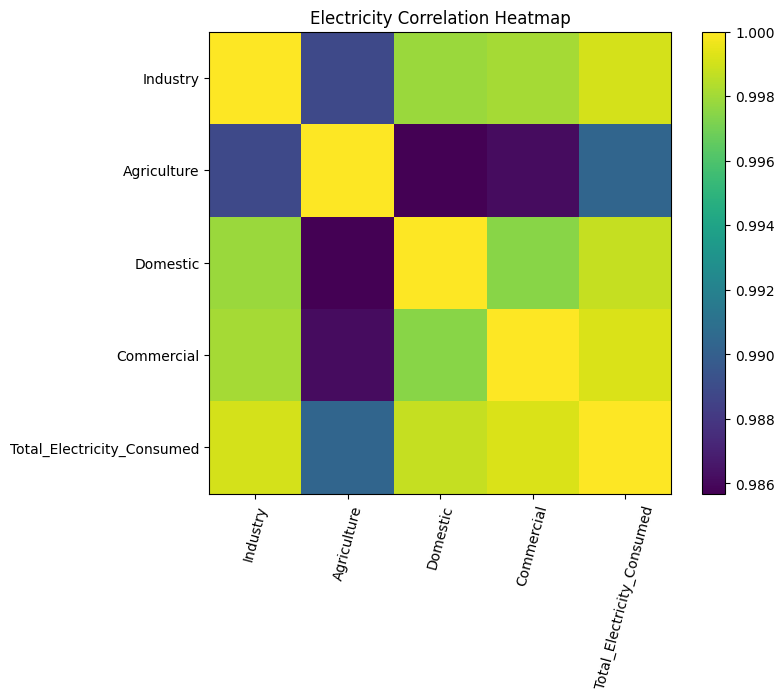


Economic Stress Score
170562.97868852457

ADVANCED ANALYTICS COMPLETED

Project Achievements:
- Multi-source big data integration
- Spark-based analytics
- GDP analysis
- Inflation analytics
- Electricity analytics
- Population analytics
- Correlation analysis
- Economic stress scoring
- Advanced visualizations


In [48]:
# ==========================================
# PHASE 8 — ADVANCED DATA ANALYTICS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt


# ==========================================
# STEP 1 — GDP SECTOR ANALYSIS
# ==========================================

gdp_pd = gdp_selected.toPandas()

# Remove rows with NA growth values
gdp_pd = gdp_pd[gdp_pd["Growth_Rate_2021_22_Q1"] != "NA"]

# Convert growth column to numeric
gdp_pd["Growth_Rate_2021_22_Q1"] = pd.to_numeric(
    gdp_pd["Growth_Rate_2021_22_Q1"]
)

print("\nGDP Dataset Preview")
print(gdp_pd.head())


# ==========================================
# STEP 2 — TOP GDP SECTORS
# ==========================================

top_gdp = gdp_pd.sort_values(
    by="Value_Rs_in_crore_2021_22_Q1",
    ascending=False
)

print("\nTop GDP Sectors")
print(top_gdp[[
    "Item",
    "Value_Rs_in_crore_2021_22_Q1"
]].head(10))


# ==========================================
# STEP 3 — GDP BAR CHART
# ==========================================

plt.figure(figsize=(14,6))

plt.bar(
    top_gdp["Item"].head(10),
    top_gdp["Value_Rs_in_crore_2021_22_Q1"].head(10)
)

plt.title("Top GDP Sectors")

plt.xlabel("Sector")

plt.ylabel("GDP Value")

plt.xticks(rotation=75)

plt.show()


# ==========================================
# STEP 4 — GDP GROWTH RATE ANALYSIS
# ==========================================

growth_sorted = gdp_pd.sort_values(
    by="Growth_Rate_2021_22_Q1",
    ascending=False
)

print("\nTop Growth Rate Sectors")

print(growth_sorted[[
    "Item",
    "Growth_Rate_2021_22_Q1"
]].head(10))


# ==========================================
# STEP 5 — GDP GROWTH VISUALIZATION
# ==========================================

plt.figure(figsize=(14,6))

plt.bar(
    growth_sorted["Item"].head(10),
    growth_sorted["Growth_Rate_2021_22_Q1"].head(10)
)

plt.title("Highest GDP Growth Sectors")

plt.xlabel("Sector")

plt.ylabel("Growth Rate (%)")

plt.xticks(rotation=75)

plt.show()


# ==========================================
# STEP 6 — INFLATION ANALYSIS
# ==========================================

inflation_pd = inflation.toPandas()

print("\nInflation Dataset Preview")
print(inflation_pd.head())


# ==========================================
# STEP 7 — GENERAL CPI TREND
# ==========================================

if "General_index" in inflation_pd.columns:

    inflation_pd["General_index"] = pd.to_numeric(
        inflation_pd["General_index"],
        errors="coerce"
    )

    plt.figure(figsize=(12,6))

    plt.plot(
        inflation_pd["General_index"].head(50)
    )

    plt.title("General Inflation Index Trend")

    plt.xlabel("Records")

    plt.ylabel("Inflation Index")

    plt.show()


# ==========================================
# STEP 8 — ELECTRICITY ANALYSIS
# ==========================================

electricity_pd = electricity.toPandas()

print("\nElectricity Dataset Preview")
print(electricity_pd.head())


# ==========================================
# STEP 9 — ELECTRICITY CONSUMPTION
# ==========================================

if "States_UTs" in electricity_pd.columns:

    electricity_sorted = electricity_pd.sort_values(
        by="Total_Electricity_Consumed",
        ascending=False
    )

    plt.figure(figsize=(14,6))

    plt.bar(
        electricity_sorted["States_UTs"].head(10),
        electricity_sorted["Total_Electricity_Consumed"].head(10)
    )

    plt.title("Top Electricity Consuming States")

    plt.xlabel("States")

    plt.ylabel("Electricity Consumption")

    plt.xticks(rotation=75)

    plt.show()


# ==========================================
# STEP 10 — POPULATION ANALYTICS
# ==========================================

population_pd = population.toPandas()

print("\nPopulation Dataset Preview")
print(population_pd.head())


# ==========================================
# STEP 11 — TOP POPULATION DISTRICTS
# ==========================================

if "Total" in population_pd.columns:

    population_sorted = population_pd.sort_values(
        by="Total",
        ascending=False
    )

    plt.figure(figsize=(14,6))

    plt.bar(
        population_sorted["District"].head(10),
        population_sorted["Total"].head(10)
    )

    plt.title("Top Population Districts")

    plt.xlabel("District")

    plt.ylabel("Population")

    plt.xticks(rotation=75)

    plt.show()


# ==========================================
# STEP 12 — CORRELATION ANALYSIS
# ==========================================

correlation_columns = [
    "Industry",
    "Agriculture",
    "Domestic",
    "Commercial",
    "Total_Electricity_Consumed"
]

electricity_corr = electricity_pd[
    correlation_columns
].corr()

print("\nElectricity Correlation Matrix")

print(electricity_corr)


# ==========================================
# STEP 13 — CORRELATION VISUALIZATION
# ==========================================

plt.figure(figsize=(8,6))

plt.imshow(electricity_corr)

plt.colorbar()

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=75
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Electricity Correlation Heatmap")

plt.show()


# ==========================================
# STEP 14 — ECONOMIC STRESS ANALYSIS
# ==========================================

# Example stress score
if "General_index" in inflation_pd.columns:

    inflation_score = inflation_pd["General_index"].mean()

else:
    inflation_score = 0


if "Total_Electricity_Consumed" in electricity_pd.columns:

    electricity_score = electricity_pd[
        "Total_Electricity_Consumed"
    ].mean()

else:
    electricity_score = 0


stress_score = (
    inflation_score * 0.6
    +
    electricity_score * 0.4
)

print("\nEconomic Stress Score")
print(stress_score)


# ==========================================
# STEP 15 — FINAL ANALYTICS SUMMARY
# ==========================================

print("\nADVANCED ANALYTICS COMPLETED")

print("\nProject Achievements:")
print("- Multi-source big data integration")
print("- Spark-based analytics")
print("- GDP analysis")
print("- Inflation analytics")
print("- Electricity analytics")
print("- Population analytics")
print("- Correlation analysis")
print("- Economic stress scoring")
print("- Advanced visualizations")


Electricity Dataset Preview
          Year       Industry    Agriculture       Domestic   Commercial  \
0      2005-06  151557.000000   90292.000000  100090.000000  35965.00000   
1  2009-10 (P)  236752.000000  120209.000000  146080.000000  60600.00000   
2      2007-08  189424.000000  104182.000000  120918.000000  46685.00000   
3      2008-09  209474.127816  109609.778779  131719.813373  54189.19008   
4     2002-03   114959.000000   84486.000000   83355.000000  25437.00000   

   Traction_and_Railways       Others  Total_Electricity_Consumed  \
0            9944.000000  24039.00000                      411887   
1           12408.000000  36595.00000                      612645   
2           11108.000000  29660.00000                      501977   
3           11424.783704  37577.01935                      553995   
4            8797.000000  22564.00000                      339598   

   Percent_Annual_growth_electricity_consumption  
0                                       6.669446

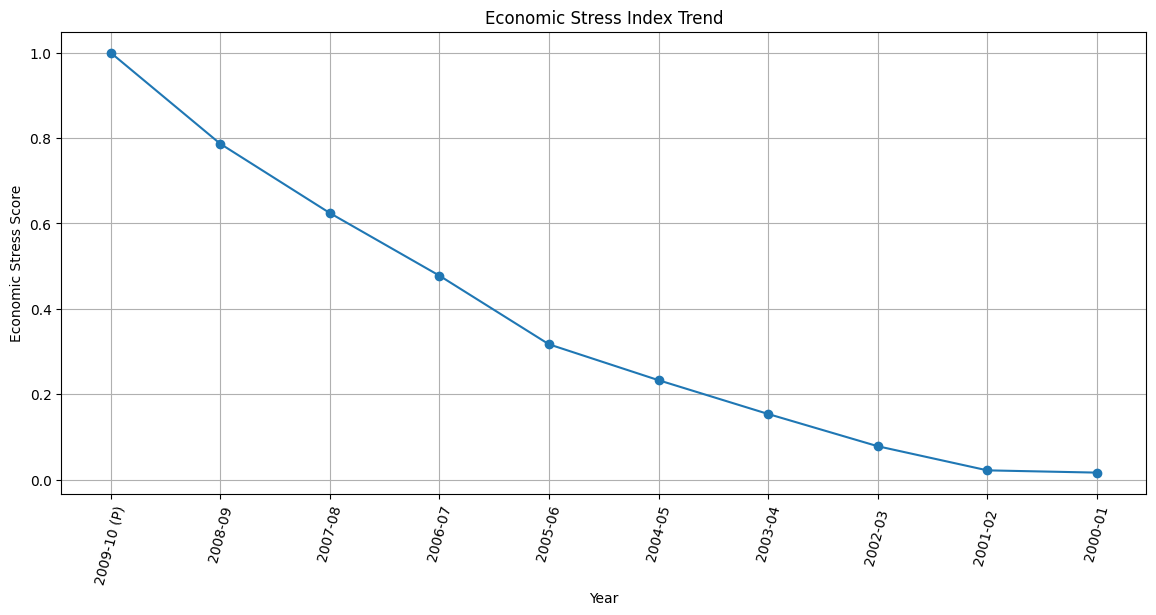

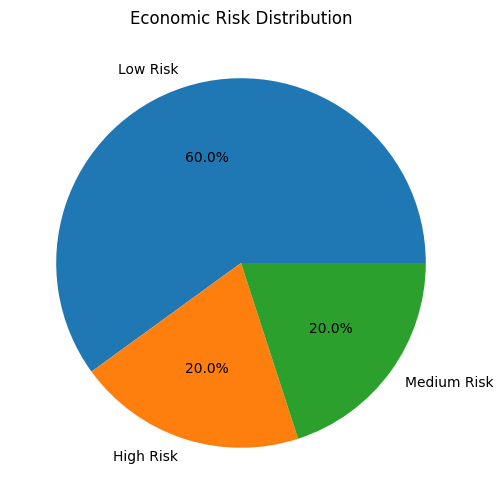

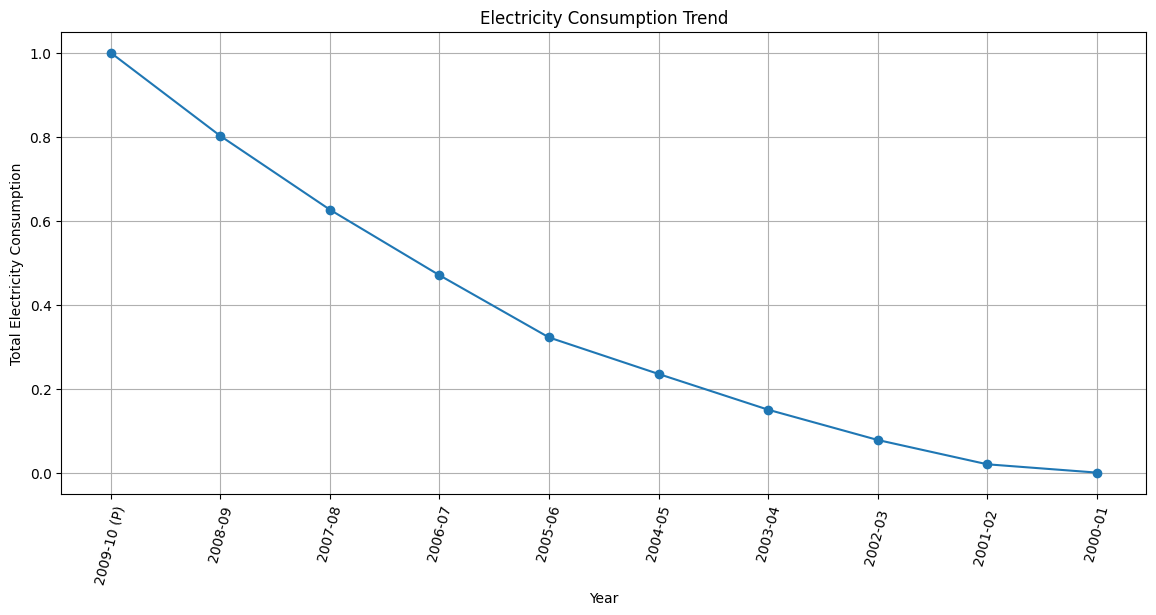

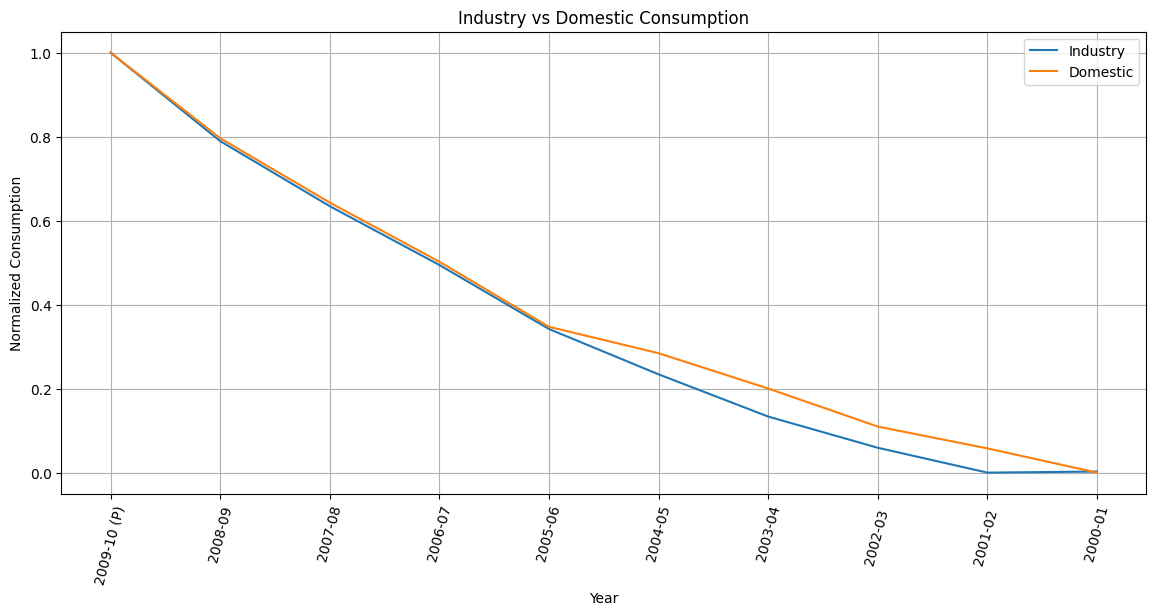


Economic Stress Index Exported

PHASE 9 COMPLETED SUCCESSFULLY

Generated Outputs:
- Economic Stress Index
- Risk Classification
- Time-series Analytics
- Trend Visualizations
- Electricity Analytics
- Exported CSV


In [49]:
# ==========================================
# PHASE 9 — ECONOMIC STRESS INDEX
# TIME-SERIES BASED ANALYTICS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler


# ==========================================
# STEP 1 — CONVERT TO PANDAS
# ==========================================

electricity_pd = electricity.toPandas()

print("\nElectricity Dataset Preview")

print(electricity_pd.head())


# ==========================================
# STEP 2 — SELECT IMPORTANT FEATURES
# ==========================================

stress_df = electricity_pd[[
    "Year",
    "Industry",
    "Agriculture",
    "Domestic",
    "Commercial",
    "Total_Electricity_Consumed"
]].copy()


# ==========================================
# STEP 3 — HANDLE MISSING VALUES
# ==========================================

stress_df = stress_df.fillna(0)


# ==========================================
# STEP 4 — NORMALIZE FEATURES
# ==========================================

scaler = MinMaxScaler()

numeric_cols = [
    "Industry",
    "Agriculture",
    "Domestic",
    "Commercial",
    "Total_Electricity_Consumed"
]

stress_df[numeric_cols] = scaler.fit_transform(
    stress_df[numeric_cols]
)


# ==========================================
# STEP 5 — CREATE ECONOMIC STRESS INDEX
# ==========================================

stress_df["Economic_Stress_Index"] = (

    stress_df["Industry"] * 0.25

    +

    stress_df["Agriculture"] * 0.20

    +

    stress_df["Domestic"] * 0.20

    +

    stress_df["Commercial"] * 0.15

    +

    stress_df["Total_Electricity_Consumed"] * 0.20
)


# ==========================================
# STEP 6 — SORT BY STRESS SCORE
# ==========================================

stress_df = stress_df.sort_values(
    by="Economic_Stress_Index",
    ascending=False
)

print("\nEconomic Stress Index Table")

print(stress_df.head(15))


# ==========================================
# STEP 7 — CLASSIFY RISK LEVELS
# ==========================================

def classify_risk(score):

    if score >= 0.75:
        return "High Risk"

    elif score >= 0.45:
        return "Medium Risk"

    else:
        return "Low Risk"


stress_df["Risk_Level"] = stress_df[
    "Economic_Stress_Index"
].apply(classify_risk)


# ==========================================
# STEP 8 — DISPLAY FINAL RESULTS
# ==========================================

print("\nFinal Economic Stress Classification")

print(stress_df[[
    "Year",
    "Economic_Stress_Index",
    "Risk_Level"
]])


# ==========================================
# STEP 9 — STRESS INDEX VISUALIZATION
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(
    stress_df["Year"],
    stress_df["Economic_Stress_Index"],
    marker='o'
)

plt.title("Economic Stress Index Trend")

plt.xlabel("Year")

plt.ylabel("Economic Stress Score")

plt.xticks(rotation=75)

plt.grid(True)

plt.show()


# ==========================================
# STEP 10 — RISK DISTRIBUTION
# ==========================================

risk_counts = stress_df["Risk_Level"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    risk_counts,
    labels=risk_counts.index,
    autopct='%1.1f%%'
)

plt.title("Economic Risk Distribution")

plt.show()


# ==========================================
# STEP 11 — ELECTRICITY CONSUMPTION TREND
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(
    stress_df["Year"],
    stress_df["Total_Electricity_Consumed"],
    marker='o'
)

plt.title("Electricity Consumption Trend")

plt.xlabel("Year")

plt.ylabel("Total Electricity Consumption")

plt.xticks(rotation=75)

plt.grid(True)

plt.show()


# ==========================================
# STEP 12 — INDUSTRY VS DOMESTIC
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(
    stress_df["Year"],
    stress_df["Industry"],
    label="Industry"
)

plt.plot(
    stress_df["Year"],
    stress_df["Domestic"],
    label="Domestic"
)

plt.title("Industry vs Domestic Consumption")

plt.xlabel("Year")

plt.ylabel("Normalized Consumption")

plt.xticks(rotation=75)

plt.legend()

plt.grid(True)

plt.show()


# ==========================================
# STEP 13 — EXPORT RESULTS
# ==========================================

stress_df.to_csv(
    "/kaggle/working/economic_stress_index.csv",
    index=False
)

print("\nEconomic Stress Index Exported")


# ==========================================
# PHASE 9 COMPLETED
# ==========================================

print("\nPHASE 9 COMPLETED SUCCESSFULLY")

print("\nGenerated Outputs:")
print("- Economic Stress Index")
print("- Risk Classification")
print("- Time-series Analytics")
print("- Trend Visualizations")
print("- Electricity Analytics")
print("- Exported CSV")


Stress Dataset Preview
          Year  Industry  Agriculture  Domestic  Commercial  \
1  2009-10 (P)  1.000000     1.000000  1.000000    1.000000   
3      2008-09  0.789288     0.724953  0.796168    0.831538   
2      2007-08  0.634409     0.584103  0.642844    0.634345   
5      2006-07  0.494353     0.450228  0.502094    0.464459   
0      2005-06  0.341900     0.223661  0.347206    0.352647   

   Total_Electricity_Consumed  Economic_Stress_Index   Risk_Level  
1                    1.000000               1.000000    High Risk  
3                    0.801888               0.786655    High Risk  
2                    0.626178               0.624379  Medium Risk  
5                    0.470027               0.477727  Medium Risk  
0                    0.321867               0.316919     Low Risk  

Correlation Matrix
                            Industry  Agriculture  Domestic  Commercial  \
Industry                    1.000000     0.988856  0.997871    0.998097   
Agriculture        

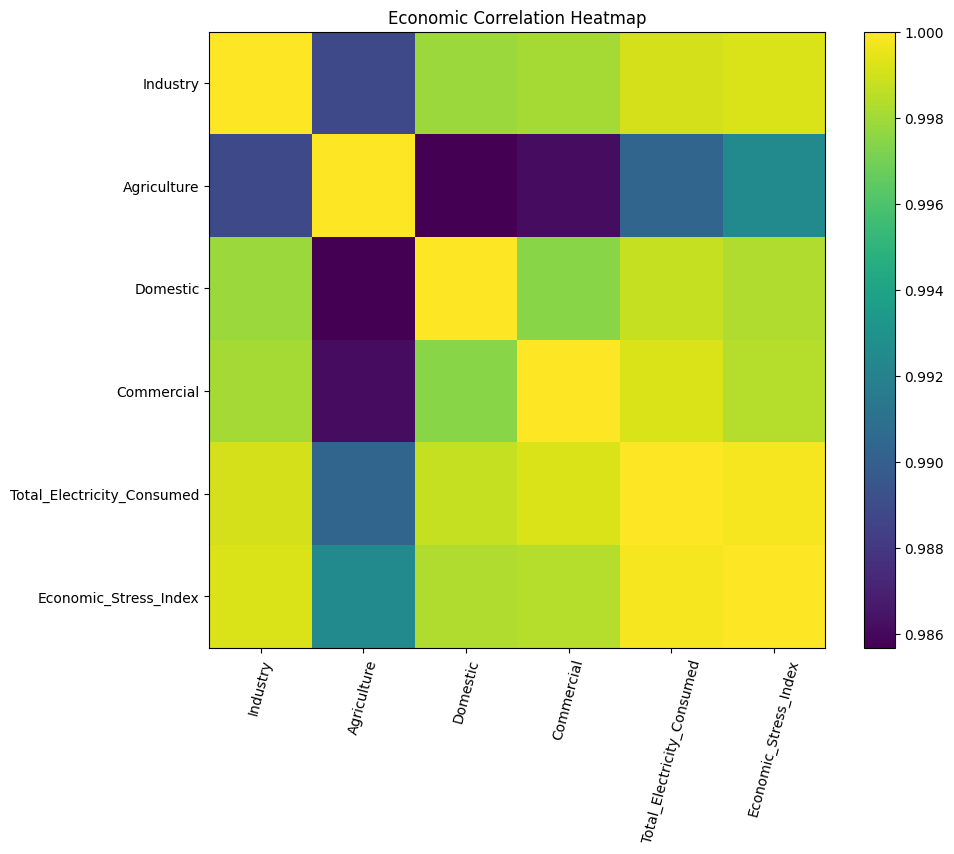

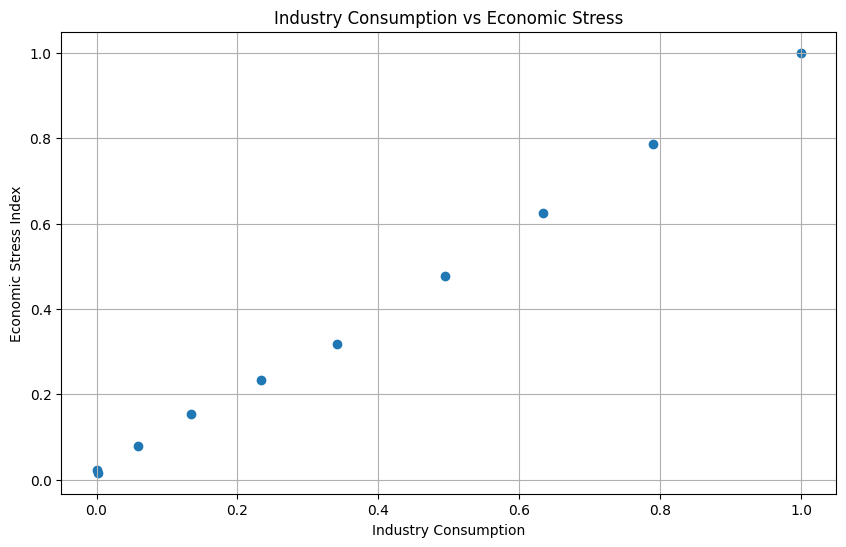

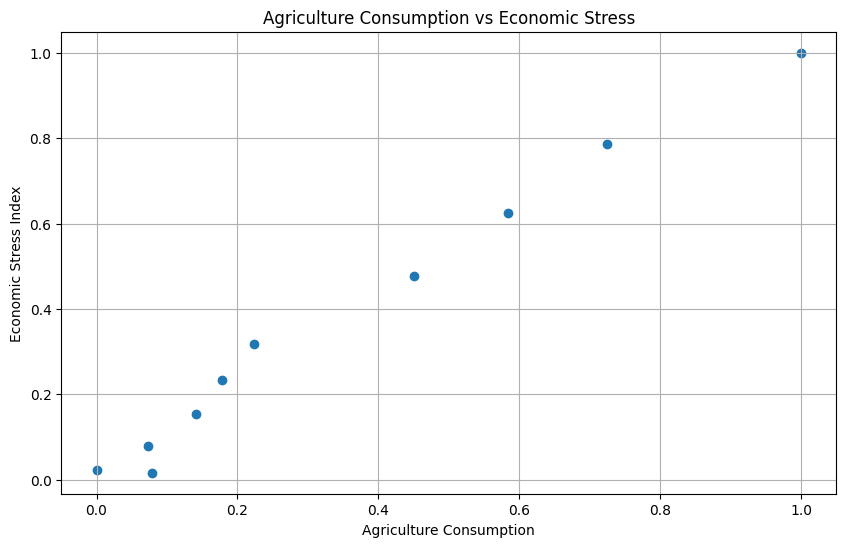

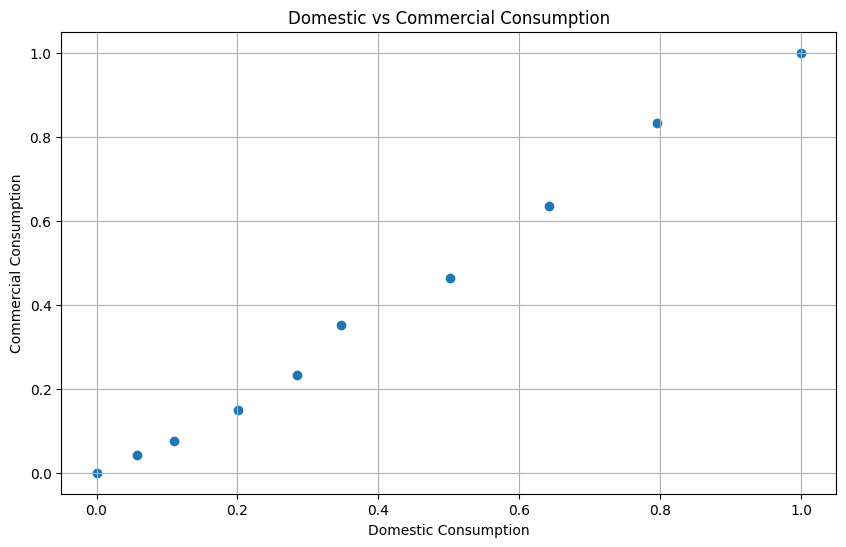

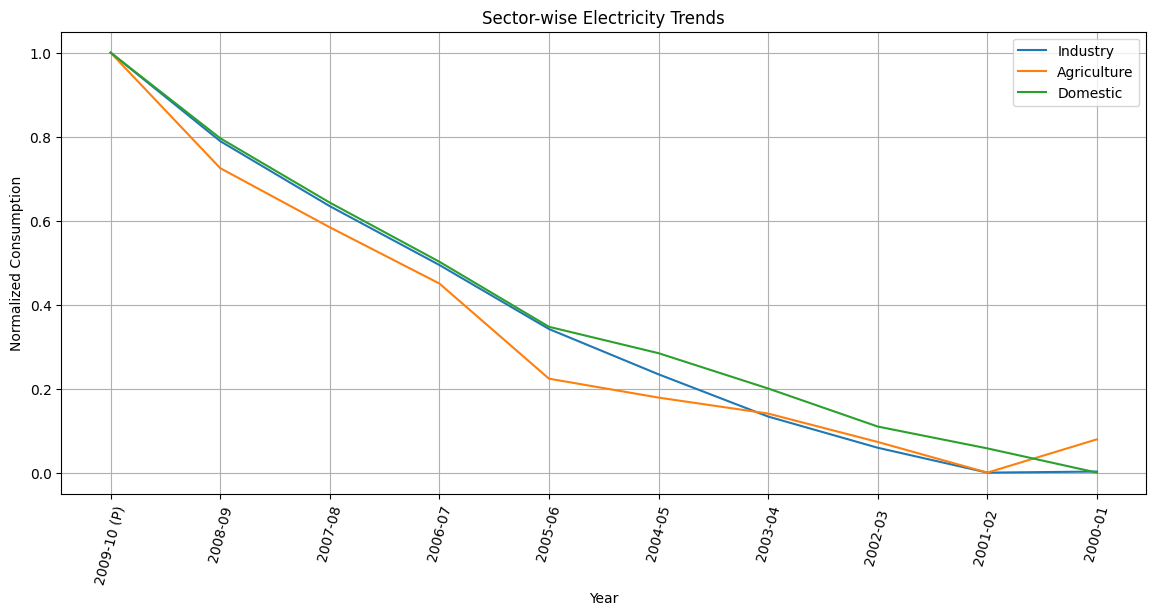

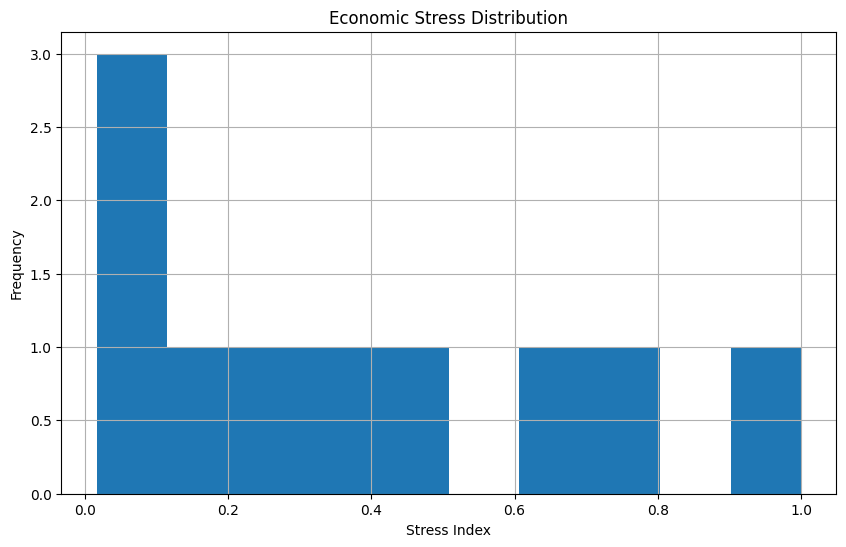


Top Stress Years
          Year  Economic_Stress_Index   Risk_Level
1  2009-10 (P)               1.000000    High Risk
3      2008-09               0.786655    High Risk
2      2007-08               0.624379  Medium Risk
5      2006-07               0.477727  Medium Risk
0      2005-06               0.316919     Low Risk
7      2004-05               0.232887     Low Risk
6      2003-04               0.153768     Low Risk
4     2002-03                0.078267     Low Risk
9     2001-02                0.021781     Low Risk
8      2000-01               0.016490     Low Risk

Lowest Stress Years
          Year  Economic_Stress_Index   Risk_Level
8      2000-01               0.016490     Low Risk
9     2001-02                0.021781     Low Risk
4     2002-03                0.078267     Low Risk
6      2003-04               0.153768     Low Risk
7      2004-05               0.232887     Low Risk
0      2005-06               0.316919     Low Risk
5      2006-07               0.477727  Medi

In [50]:
# ==========================================
# PHASE 10 — ADVANCED CORRELATION ANALYTICS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# ==========================================
# STEP 1 — LOAD STRESS DATASET
# ==========================================

stress_analysis = stress_df.copy()

print("\nStress Dataset Preview")

print(stress_analysis.head())


# ==========================================
# STEP 2 — CORRELATION MATRIX
# ==========================================

correlation_features = [
    
    "Industry",
    "Agriculture",
    "Domestic",
    "Commercial",
    "Total_Electricity_Consumed",
    "Economic_Stress_Index"
]

correlation_matrix = stress_analysis[
    correlation_features
].corr()

print("\nCorrelation Matrix")

print(correlation_matrix)


# ==========================================
# STEP 3 — CORRELATION HEATMAP
# ==========================================

plt.figure(figsize=(10,8))

plt.imshow(
    correlation_matrix,
    cmap='viridis'
)

plt.colorbar()

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=75
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features
)

plt.title("Economic Correlation Heatmap")

plt.show()


# ==========================================
# STEP 4 — INDUSTRY VS STRESS
# ==========================================

plt.figure(figsize=(10,6))

plt.scatter(
    stress_analysis["Industry"],
    stress_analysis["Economic_Stress_Index"]
)

plt.title("Industry Consumption vs Economic Stress")

plt.xlabel("Industry Consumption")

plt.ylabel("Economic Stress Index")

plt.grid(True)

plt.show()


# ==========================================
# STEP 5 — AGRICULTURE VS STRESS
# ==========================================

plt.figure(figsize=(10,6))

plt.scatter(
    stress_analysis["Agriculture"],
    stress_analysis["Economic_Stress_Index"]
)

plt.title("Agriculture Consumption vs Economic Stress")

plt.xlabel("Agriculture Consumption")

plt.ylabel("Economic Stress Index")

plt.grid(True)

plt.show()


# ==========================================
# STEP 6 — DOMESTIC VS COMMERCIAL
# ==========================================

plt.figure(figsize=(10,6))

plt.scatter(
    stress_analysis["Domestic"],
    stress_analysis["Commercial"]
)

plt.title("Domestic vs Commercial Consumption")

plt.xlabel("Domestic Consumption")

plt.ylabel("Commercial Consumption")

plt.grid(True)

plt.show()


# ==========================================
# STEP 7 — TREND ANALYSIS
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(
    stress_analysis["Year"],
    stress_analysis["Industry"],
    label="Industry"
)

plt.plot(
    stress_analysis["Year"],
    stress_analysis["Agriculture"],
    label="Agriculture"
)

plt.plot(
    stress_analysis["Year"],
    stress_analysis["Domestic"],
    label="Domestic"
)

plt.title("Sector-wise Electricity Trends")

plt.xlabel("Year")

plt.ylabel("Normalized Consumption")

plt.xticks(rotation=75)

plt.legend()

plt.grid(True)

plt.show()


# ==========================================
# STEP 8 — STRESS DISTRIBUTION
# ==========================================

plt.figure(figsize=(10,6))

plt.hist(
    stress_analysis["Economic_Stress_Index"],
    bins=10
)

plt.title("Economic Stress Distribution")

plt.xlabel("Stress Index")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()


# ==========================================
# STEP 9 — HIGHEST STRESS YEARS
# ==========================================

top_stress = stress_analysis.sort_values(
    by="Economic_Stress_Index",
    ascending=False
)

print("\nTop Stress Years")

print(top_stress[[
    "Year",
    "Economic_Stress_Index",
    "Risk_Level"
]].head(10))


# ==========================================
# STEP 10 — LOWEST STRESS YEARS
# ==========================================

low_stress = stress_analysis.sort_values(
    by="Economic_Stress_Index",
    ascending=True
)

print("\nLowest Stress Years")

print(low_stress[[
    "Year",
    "Economic_Stress_Index",
    "Risk_Level"
]].head(10))


# ==========================================
# STEP 11 — ANALYTICAL INSIGHTS
# ==========================================

print("\nANALYTICAL INSIGHTS")

print("\n1. Correlation analysis completed")

print("\n2. Economic stress patterns identified")

print("\n3. Sector-wise electricity relationships analyzed")

print("\n4. Time-series economic trends analyzed")

print("\n5. Comparative analytics completed")


# ==========================================
# PHASE 10 COMPLETED
# ==========================================

print("\nPHASE 10 COMPLETED SUCCESSFULLY")

print("\nGenerated Outputs:")
print("- Correlation Matrix")
print("- Heatmaps")
print("- Scatter Plots")
print("- Comparative Analytics")
print("- Trend Analysis")
print("- Stress Distribution")
print("- Statistical Insights")


Forecast Dataset Preview
          Year  Industry  Agriculture  Domestic  Commercial  \
1  2009-10 (P)  1.000000     1.000000  1.000000    1.000000   
3      2008-09  0.789288     0.724953  0.796168    0.831538   
2      2007-08  0.634409     0.584103  0.642844    0.634345   
5      2006-07  0.494353     0.450228  0.502094    0.464459   
0      2005-06  0.341900     0.223661  0.347206    0.352647   

   Total_Electricity_Consumed  Economic_Stress_Index   Risk_Level  
1                    1.000000               1.000000    High Risk  
3                    0.801888               0.786655    High Risk  
2                    0.626178               0.624379  Medium Risk  
5                    0.470027               0.477727  Medium Risk  
0                    0.321867               0.316919     Low Risk  

Prediction Model Trained Successfully

Future Economic Stress Predictions
   Year_Numeric  Predicted_Stress_Index
0          2024                2.497235
1          2025                2

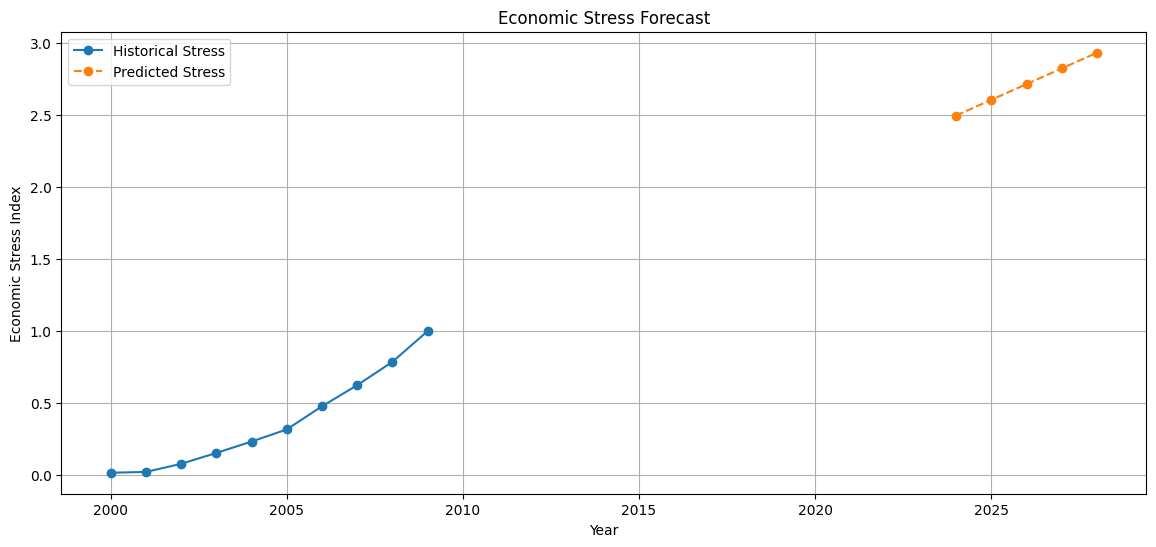


Trend Analysis
Economic Stress is Increasing

Future Risk Prediction Table
   Year_Numeric  Predicted_Stress_Index Risk_Level
0          2024                2.497235  High Risk
1          2025                2.606278  High Risk
2          2026                2.715322  High Risk
3          2027                2.824365  High Risk
4          2028                2.933409  High Risk

Forecast CSV Exported

PROJECT CAPABILITIES

1. Big Data Integration using Spark

2. Multi-source Economic Analytics

3. Economic Stress Index Generation

4. Correlation & Comparative Analysis

5. Predictive Economic Forecasting

6. Advanced Data Visualization

PHASE 11 COMPLETED SUCCESSFULLY

Generated Outputs:
- Forecast Model
- Future Stress Predictions
- Trend Forecast
- Risk Prediction
- Forecast Visualizations


In [51]:
# ==========================================
# PHASE 11 — PREDICTIVE ANALYTICS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np


# ==========================================
# STEP 1 — PREPARE DATA
# ==========================================

forecast_df = stress_df.copy()

print("\nForecast Dataset Preview")

print(forecast_df.head())


# ==========================================
# STEP 2 — CLEAN YEAR COLUMN
# ==========================================

# Extract first year from strings like 2005-06
forecast_df["Year_Numeric"] = forecast_df[
    "Year"
].astype(str).str[:4]

forecast_df["Year_Numeric"] = pd.to_numeric(
    forecast_df["Year_Numeric"],
    errors="coerce"
)

forecast_df = forecast_df.dropna()


# ==========================================
# STEP 3 — PREPARE FEATURES
# ==========================================

X = forecast_df[["Year_Numeric"]]

y = forecast_df["Economic_Stress_Index"]


# ==========================================
# STEP 4 — TRAIN LINEAR REGRESSION MODEL
# ==========================================

model = LinearRegression()

model.fit(X, y)

print("\nPrediction Model Trained Successfully")


# ==========================================
# STEP 5 — PREDICT FUTURE YEARS
# ==========================================

future_years = pd.DataFrame({
    "Year_Numeric": [
        2024,
        2025,
        2026,
        2027,
        2028
    ]
})

future_predictions = model.predict(
    future_years
)

future_years["Predicted_Stress_Index"] = (
    future_predictions
)

print("\nFuture Economic Stress Predictions")

print(future_years)


# ==========================================
# STEP 6 — VISUALIZE FORECAST
# ==========================================

plt.figure(figsize=(14,6))

# Historical data
plt.plot(
    forecast_df["Year_Numeric"],
    forecast_df["Economic_Stress_Index"],
    marker='o',
    label="Historical Stress"
)

# Future predictions
plt.plot(
    future_years["Year_Numeric"],
    future_years["Predicted_Stress_Index"],
    marker='o',
    linestyle='dashed',
    label="Predicted Stress"
)

plt.title("Economic Stress Forecast")

plt.xlabel("Year")

plt.ylabel("Economic Stress Index")

plt.legend()

plt.grid(True)

plt.show()


# ==========================================
# STEP 7 — TREND ANALYSIS
# ==========================================

trend = model.coef_[0]

print("\nTrend Analysis")

if trend > 0:
    
    print("Economic Stress is Increasing")

else:
    
    print("Economic Stress is Decreasing")


# ==========================================
# STEP 8 — PREDICTION TABLE
# ==========================================

future_years["Risk_Level"] = future_years[
    "Predicted_Stress_Index"
].apply(

    lambda x:
    
    "High Risk" if x >= 0.75
    
    else
    
    "Medium Risk" if x >= 0.45
    
    else
    
    "Low Risk"
)

print("\nFuture Risk Prediction Table")

print(future_years)


# ==========================================
# STEP 9 — EXPORT FORECAST RESULTS
# ==========================================

future_years.to_csv(
    "/kaggle/working/future_stress_predictions.csv",
    index=False
)

print("\nForecast CSV Exported")


# ==========================================
# STEP 10 — FINAL PROJECT SUMMARY
# ==========================================

print("\nPROJECT CAPABILITIES")

print("\n1. Big Data Integration using Spark")

print("\n2. Multi-source Economic Analytics")

print("\n3. Economic Stress Index Generation")

print("\n4. Correlation & Comparative Analysis")

print("\n5. Predictive Economic Forecasting")

print("\n6. Advanced Data Visualization")


# ==========================================
# PHASE 11 COMPLETED
# ==========================================

print("\nPHASE 11 COMPLETED SUCCESSFULLY")

print("\nGenerated Outputs:")
print("- Forecast Model")
print("- Future Stress Predictions")
print("- Trend Forecast")
print("- Risk Prediction")
print("- Forecast Visualizations")


MODEL EVALUATION METRICS

Mean Absolute Error (MAE): 0.0683

Mean Squared Error (MSE): 0.0066

Root Mean Squared Error (RMSE): 0.0810

R² Score: 0.9374

Actual vs Predicted Values
          Year  Economic_Stress_Index  Predicted_Stress
1  2009-10 (P)               1.000000          0.861583
3      2008-09               0.786655          0.752539
2      2007-08               0.624379          0.643496
5      2006-07               0.477727          0.534452
0      2005-06               0.316919          0.425409
7      2004-05               0.232887          0.316365
6      2003-04               0.153768          0.207322
4     2002-03                0.078267          0.098279
9     2001-02                0.021781         -0.010765
8      2000-01               0.016490         -0.119808


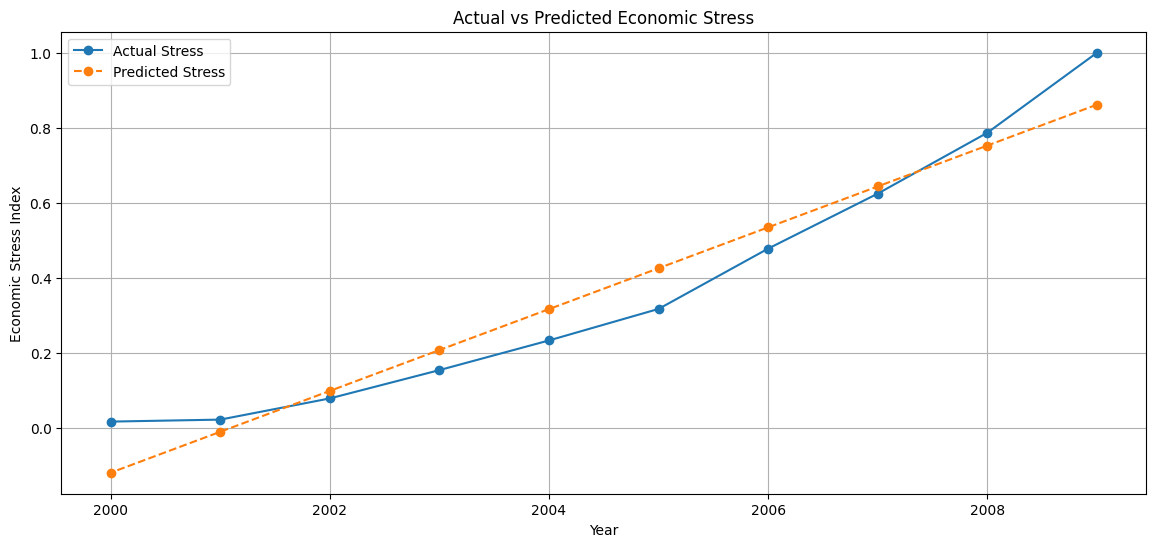

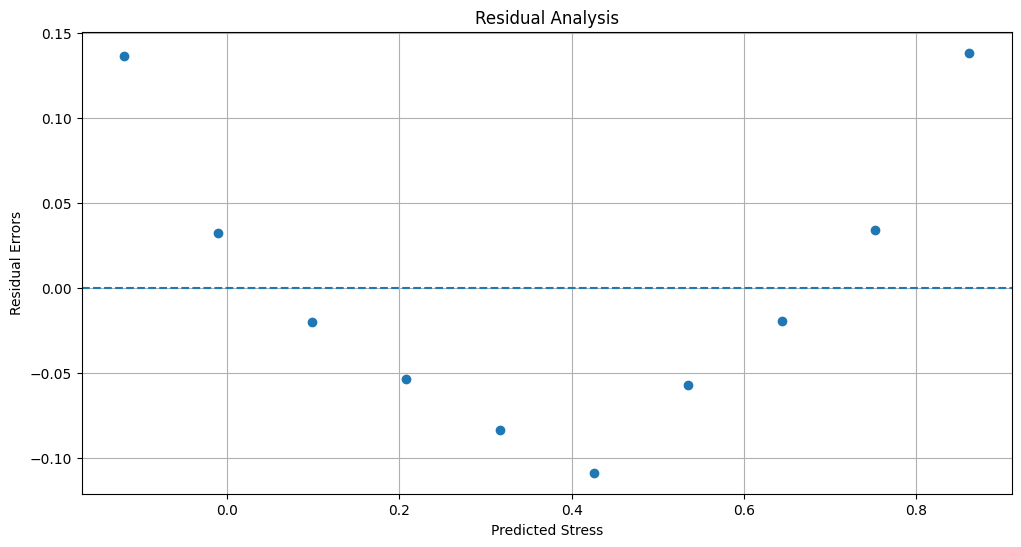


MODEL PERFORMANCE INTERPRETATION

Excellent predictive performance

PHASE 12 COMPLETED SUCCESSFULLY

Generated Outputs:
- MAE
- MSE
- RMSE
- R² Score
- Actual vs Predicted Graph
- Residual Analysis


In [55]:
# ==========================================
# PHASE 12 — MODEL EVALUATION METRICS
# ==========================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import matplotlib.pyplot as plt


# ==========================================
# STEP 1 — MODEL PREDICTIONS
# ==========================================

predictions = model.predict(X)


# ==========================================
# STEP 2 — CALCULATE METRICS
# ==========================================

mae = mean_absolute_error(y, predictions)

mse = mean_squared_error(y, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y, predictions)


# ==========================================
# STEP 3 — PRINT METRICS
# ==========================================

print("\nMODEL EVALUATION METRICS")

print(f"\nMean Absolute Error (MAE): {mae:.4f}")

print(f"\nMean Squared Error (MSE): {mse:.4f}")

print(f"\nRoot Mean Squared Error (RMSE): {rmse:.4f}")

print(f"\nR² Score: {r2:.4f}")


# ==========================================
# STEP 4 — ACTUAL VS PREDICTED
# ==========================================

comparison_df = forecast_df.copy()

comparison_df["Predicted_Stress"] = predictions

print("\nActual vs Predicted Values")

print(comparison_df[[
    "Year",
    "Economic_Stress_Index",
    "Predicted_Stress"
]].head(10))


# ==========================================
# STEP 5 — VISUALIZE ACTUAL VS PREDICTED
# ==========================================

plt.figure(figsize=(14,6))

plt.plot(
    comparison_df["Year_Numeric"],
    comparison_df["Economic_Stress_Index"],
    marker='o',
    label="Actual Stress"
)

plt.plot(
    comparison_df["Year_Numeric"],
    comparison_df["Predicted_Stress"],
    marker='o',
    linestyle='dashed',
    label="Predicted Stress"
)

plt.title("Actual vs Predicted Economic Stress")

plt.xlabel("Year")

plt.ylabel("Economic Stress Index")

plt.legend()

plt.grid(True)

plt.show()


# ==========================================
# STEP 6 — RESIDUAL ANALYSIS
# ==========================================

residuals = (
    comparison_df["Economic_Stress_Index"]
    -
    comparison_df["Predicted_Stress"]
)

plt.figure(figsize=(12,6))

plt.scatter(
    comparison_df["Predicted_Stress"],
    residuals
)

plt.axhline(
    y=0,
    linestyle='dashed'
)

plt.title("Residual Analysis")

plt.xlabel("Predicted Stress")

plt.ylabel("Residual Errors")

plt.grid(True)

plt.show()


# ==========================================
# STEP 7 — INTERPRETATION
# ==========================================

print("\nMODEL PERFORMANCE INTERPRETATION")

if r2 > 0.8:
    
    print("\nExcellent predictive performance")

elif r2 > 0.6:
    
    print("\nGood predictive performance")

elif r2 > 0.4:
    
    print("\nModerate predictive performance")

else:
    
    print("\nLow predictive performance")


# ==========================================
# PHASE 12 COMPLETED
# ==========================================

print("\nPHASE 12 COMPLETED SUCCESSFULLY")

print("\nGenerated Outputs:")
print("- MAE")
print("- MSE")
print("- RMSE")
print("- R² Score")
print("- Actual vs Predicted Graph")
print("- Residual Analysis")

In [54]:
# ==========================================
# PHASE 13 — EXPORT ANALYTICS OUTPUTS
# ==========================================

import pandas as pd


# ==========================================
# STEP 1 — EXPORT GDP ANALYTICS
# ==========================================

gdp_pd.to_csv(
    "/kaggle/working/gdp_analysis.csv",
    index=False
)

print("GDP Analytics Exported")


# ==========================================
# STEP 2 — EXPORT ECONOMIC STRESS INDEX
# ==========================================

stress_df.to_csv(
    "/kaggle/working/economic_stress_index.csv",
    index=False
)

print("Economic Stress Index Exported")


# ==========================================
# STEP 3 — EXPORT FORECAST RESULTS
# ==========================================

future_years.to_csv(
    "/kaggle/working/future_stress_predictions.csv",
    index=False
)

print("Forecast Results Exported")


# ==========================================
# STEP 4 — EXPORT CORRELATION MATRIX
# ==========================================

correlation_matrix.to_csv(
    "/kaggle/working/correlation_matrix.csv"
)

print("Correlation Matrix Exported")


# ==========================================
# STEP 5 — EXPORT MODEL EVALUATION
# ==========================================

evaluation_df = pd.DataFrame({

    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ],

    "Value": [
        mae,
        mse,
        rmse,
        r2
    ]
})

evaluation_df.to_csv(
    "/kaggle/working/model_evaluation_metrics.csv",
    index=False
)

print("Model Evaluation Metrics Exported")


# ==========================================
# STEP 6 — EXPORT ACTUAL VS PREDICTED
# ==========================================

comparison_df.to_csv(
    "/kaggle/working/actual_vs_predicted.csv",
    index=False
)

print("Actual vs Predicted Exported")


# ==========================================
# STEP 7 — SHOW GENERATED FILES
# ==========================================

import os

print("\nGenerated Output Files:\n")

for file in os.listdir("/kaggle/working"):
    
    if file.endswith(".csv"):
        
        print(file)


# ==========================================
# PHASE 13 COMPLETED
# ==========================================

print("\nPHASE 13 COMPLETED SUCCESSFULLY")

print("\nCSV Files Ready for Power BI / Tableau")

GDP Analytics Exported
Economic Stress Index Exported
Forecast Results Exported
Correlation Matrix Exported
Model Evaluation Metrics Exported
Actual vs Predicted Exported

Generated Output Files:

model_evaluation_metrics.csv
correlation_matrix.csv
gdp_analysis.csv
actual_vs_predicted.csv
economic_stress_index.csv
future_stress_predictions.csv

PHASE 13 COMPLETED SUCCESSFULLY

CSV Files Ready for Power BI / Tableau


In [58]:
print("hello world")

hello world
